# Сегментация изображений: от обычной CNN к U-Net

В задаче классификации сеть давала один ответ на одно входное изображение. Но что делать, если мы хотим классифицировать каждый пиксель?
Например, определять, какие пиксели относятся к объекту, а какие - к фону?
Такую задачу называют **семантической сегментацией**.

Сначала сравним три задачи на одной сцене с людьми из датасета [Penn-Fudan](https://www.cis.upenn.edu/~jshi/ped_html/).

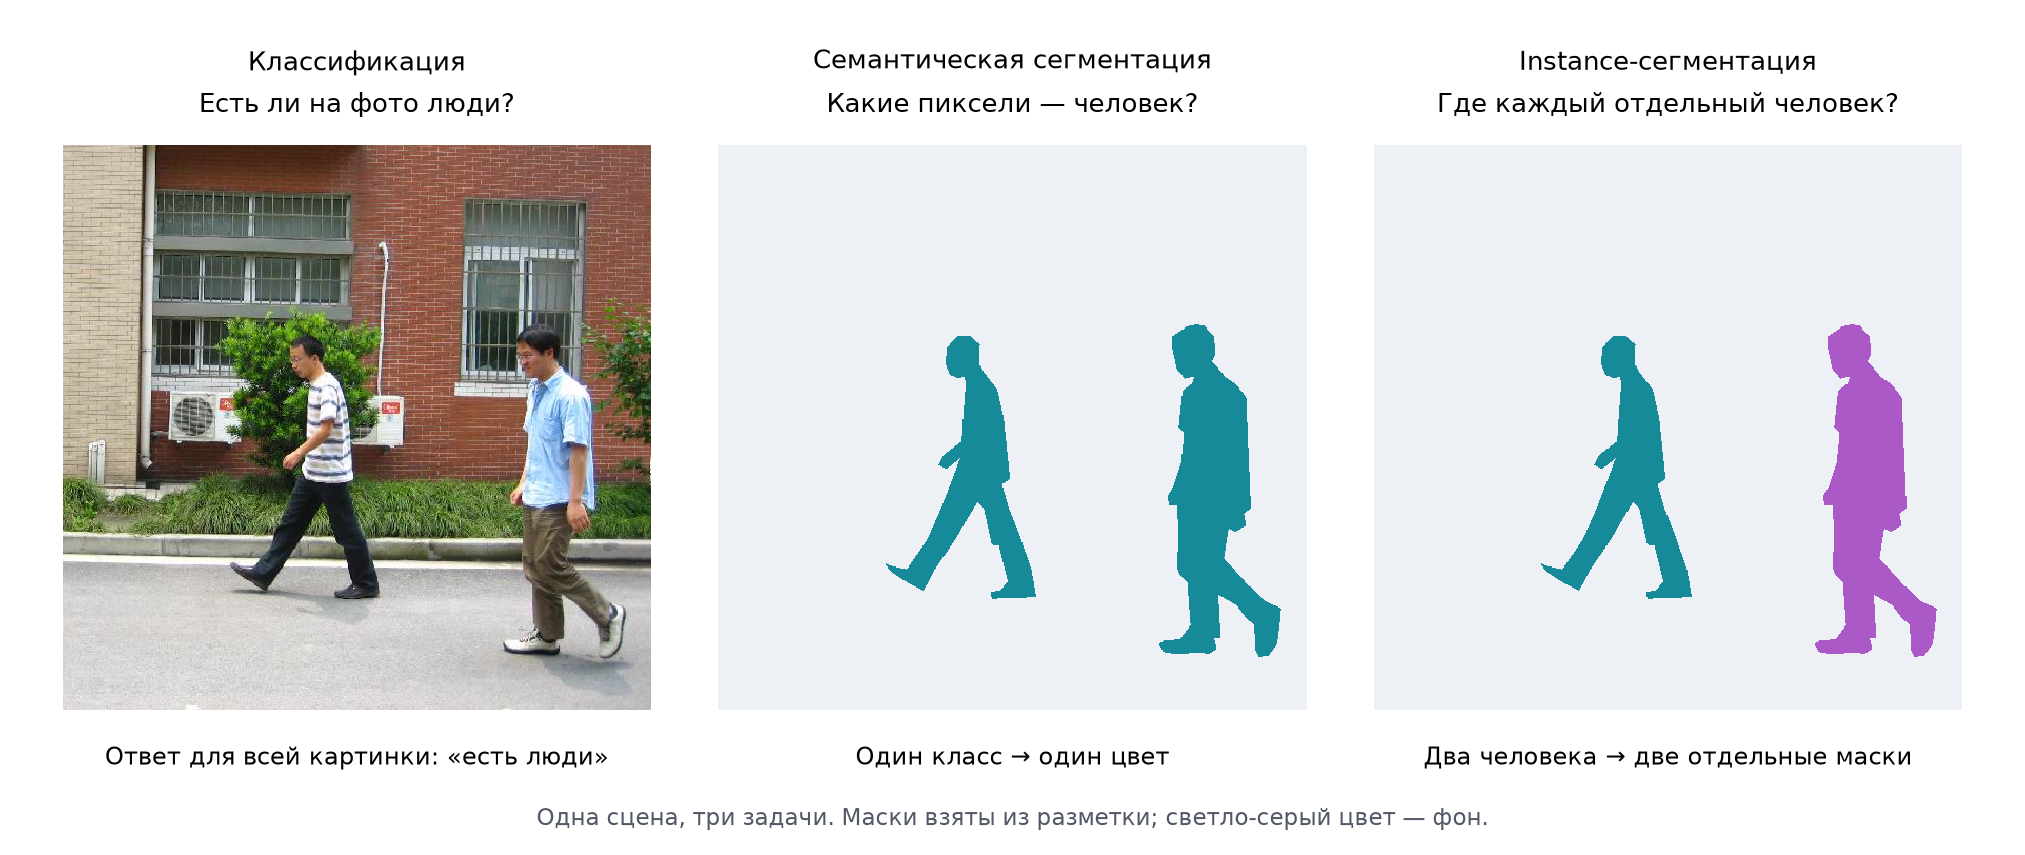



- **Классификация:** «на фото есть люди». Где именно - из ответа не узнать.
- **Семантическая сегментация:** каждый пиксель получает класс. Все люди одного цвета.
- **Instance-сегментация:** у каждого человека отдельная маска. Разные цвета - разные
  экземпляры одного класса, а не разные классы.

Подробнее про задачи можно прочитать в учебнике В. В. Китова: [семантическая сегментация](https://deepmachinelearning.ru/docs/Neural-networks/Semantic-segmentation/Semantic-segmentation-task)
и [сегментация объектов](https://deepmachinelearning.ru/docs/Neural-networks/Instance-segmentation/Problem-statement).

В этом ноутбуке мы рассмотрим задачу сегментации ядер клеток из биологии:

1. Посмотрим на ядра и их маски: где теряются детали и как аугментация может испортить разметку.
2. Обучим обычную свёрточную сеть.
3. Разберём устройство U-Net и сравним её с первой сетью на тех же снимках.
4. Найдём ошибки, посмотрим на вероятности и сохраним модель.
5. В дополнительном разделе соберём новые синтетические train-примеры из вырезанных ядер.

Загрузите только этот notebook в Colab/Kaggle и нажмите **Run all**.
Нужен интернет для загрузки около **81 МБ**. GPU ускорит работу, но можно и на CPU.
В Kaggle включите переключатель Internet.

In [3]:
import importlib.util
import subprocess
import sys
packages = {"torch": "torch>=2.5", "numpy": "numpy", "matplotlib": "matplotlib",
            "PIL": "Pillow>=10", "scipy": "scipy"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

import random
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image
from scipy import ndimage
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
CROP_SIZE = 128             # фрагмент исходного снимка, без уменьшения
CROPS_PER_IMAGE = 2         # новые случайные фрагменты на каждой эпохе
BATCH_SIZE = 8
EPOCHS = 8                  # 25 шагов на эпоху, 200 шагов на каждую модель
LEARNING_RATE = 0.001
PERCENTILES = (1, 99.8)      # нормализация яркости каждого снимка
WORK = (Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()) / "segmentation_lab"
WORK.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(SEED)
print("PyTorch:", torch.__version__, "| устройство:", DEVICE)


PyTorch: 2.14.1+cu130 | устройство: cuda


## 1. Сначала посмотрим на задачу

Возьмём датасет [BBBC039v1](https://bbbc.broadinstitute.org/BBBC039): **200 снимков разрешения
520×696 и около 23 тысяч размеченных клеточных ядер**. Это флуоресцентная микроскопия:
ядра светятся на тёмном фоне. Похожие локальные формы повторяются много раз,
поэтому небольшая сеть может научиться выделять их с нуля.

Этот набор удобен для нашего опыта, потому что на нем можно увидеть, насколько точно
сеть проводит контур и как сохраняет узкие промежутки между соседними ядрами.
Обе модели обучим с нуля без предобученных весов.

У авторов уже есть разбиение: **100 train / 50 validation / 50 test**. Для размножения обучающей выборки будем делать случайные кропы из изображений и масок с теми же координатами - так из одного трейн изображения мы можем получить много примеров для обучения модели.
Сначала разделяем снимки на выборки, и только потом вырезаем фрагменты (кропы) изображений:
соседние кусочки одного изображения датасета не должны оказаться и в train, и в validation.
Test оценим один раз в конце после выбора финальной модели.

Маска хранится в PNG с несколькими каналами. По
[инструкции авторов](https://gist.github.com/jccaicedo/15e811722fca51e3ae90e8b43057f075)
берём **первый канал**: `0` означает фон, положительные значения выделяют ядра.
Для нашей бинарной задачи все положительные значения превратим в `1`.

Исходная разметка позволяет различать отдельные ядра (instance сегментация). В основном уроке будем решать задачу
семантической сегментации «ядро / фон»: соприкасающиеся ядра могут составлять одну
связную область.

In [4]:
import hashlib
import shutil
import urllib.request
import zipfile

DATA = WORK / "bbbc039"
DATA.mkdir(exist_ok=True)
archives = {
    "images.zip": "6f30a5d4fe38c928ded972704f085975f8dc0d65d9aa366df00e5a9d449fddd7",
    "masks.zip": "f9e6043d8ca56344a4886f96a700d804d6ee982f31e2b2cd3194af2a053c2710",
    "metadata.zip": "a2c1f900bed9ba92a99553efd4c2ae98598433691c7401d818653ab61110deb2",
}
for filename, expected_sha in archives.items():
    archive = DATA / filename
    if not archive.exists():
        print("Скачиваем", filename)
        temporary = archive.with_suffix(".part")
        url = "https://data.broadinstitute.org/bbbc/BBBC039/" + filename
        with urllib.request.urlopen(url, timeout=60) as response, temporary.open("wb") as output:
            shutil.copyfileobj(response, output)
        with temporary.open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_sha:
                raise ValueError("Неполная загрузка: повторите ячейку")
        temporary.replace(archive)
    with archive.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected_sha:
            raise ValueError(f"Контрольная сумма не совпала: удалите {archive} и повторите загрузку")
    marker = DATA / (filename + ".extracted")
    if not marker.exists():
        with zipfile.ZipFile(archive) as z:
            for member in z.infolist():
                path = Path(member.filename)
                if path.is_absolute() or ".." in path.parts:
                    raise ValueError("Некорректный путь в архиве")
                if not member.is_dir() and "__MACOSX" not in path.parts:
                    z.extract(member, DATA)
        marker.touch()

def split_names(filename):
    return [Path(line.strip()).stem for line in (DATA / "metadata" / filename).read_text().splitlines() if line.strip()]

train_names = split_names("training.txt")
val_names = split_names("validation.txt")
test_names = split_names("test.txt")
assert not (set(train_names) & set(val_names) or set(train_names + val_names) & set(test_names))
print(f"train: {len(train_names)}, validation: {len(val_names)}, test: {len(test_names)}")


Скачиваем images.zip
Скачиваем masks.zip
Скачиваем metadata.zip
train: 100, validation: 50, test: 50


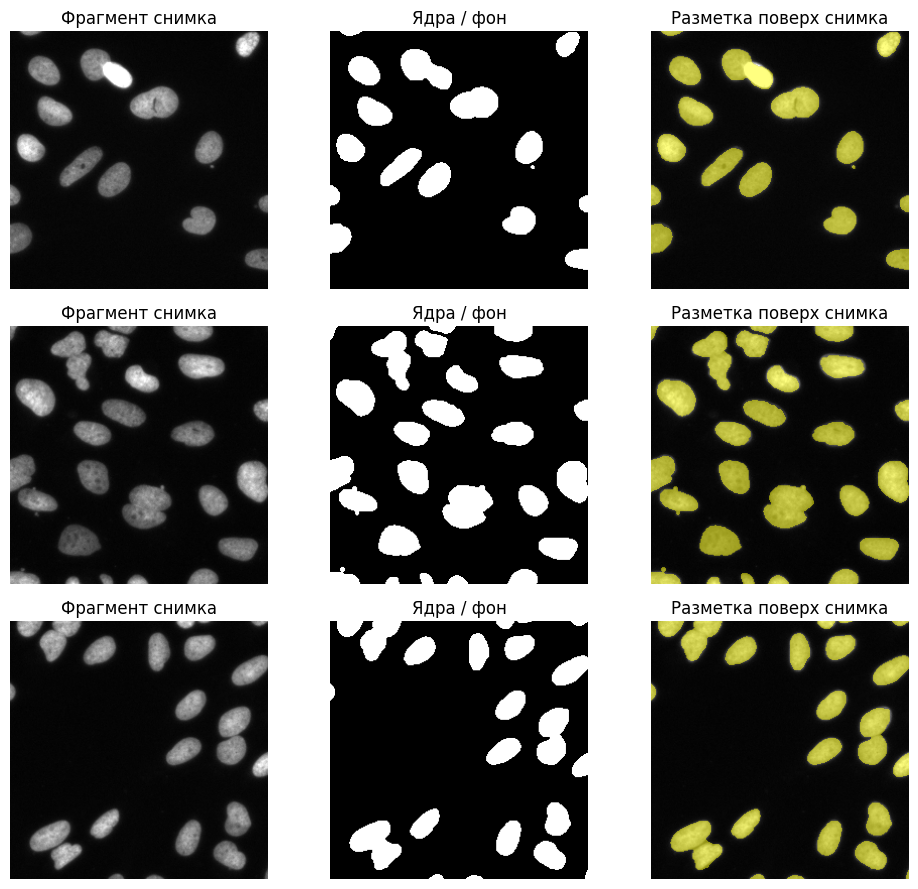

Полный снимок: (520, 696) | нормализованная яркость: 0.0 1.0
Маска: (520, 696) | метки: [0 1]


In [5]:
def load_image(path, percentiles=PERCENTILES):
    with Image.open(path) as source:
        image = np.asarray(source, dtype=np.float32)
    low, high = np.percentile(image, percentiles)
    return np.clip((image - low) / max(high - low, 1), 0, 1).astype(np.float32)

def read_pair(name):
    image = load_image(DATA / "images" / f"{name}.tif")
    with Image.open(DATA / "masks" / f"{name}.png") as source:
        mask = (np.asarray(source)[..., 0] > 0).astype(np.uint8)
    return image, mask

def center_crop(array, size=256):
    height, width = array.shape[:2]
    top, left = (height-size)//2, (width-size)//2
    return array[top:top+size, left:left+size]

def show_examples(names):
    fig, axes = plt.subplots(len(names), 3, figsize=(10, 3 * len(names)), squeeze=False)
    for row, name in zip(axes, names):
        image, mask = read_pair(name)
        image, mask = center_crop(image), center_crop(mask)
        row[0].imshow(image, cmap="gray", vmin=0, vmax=1)
        row[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        row[2].imshow(image, cmap="gray", vmin=0, vmax=1)
        row[2].imshow(np.ma.masked_where(mask != 1, mask), cmap="autumn", alpha=.5, vmin=0, vmax=1)
        for ax, title in zip(row, ["Фрагмент снимка", "Ядра / фон", "Разметка поверх снимка"]):
            ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()

show_examples([train_names[i] for i in [0, 20, 40]])
image, mask = read_pair(train_names[0])
print("Полный снимок:", image.shape, "| нормализованная яркость:", image.min(), image.max())
print("Маска:", mask.shape, "| метки:", np.unique(mask))


### Почему яркость нормализуется отдельно?

Данные приходят в формате TIFF - он содержит 16-битные значения, поэтому привычное деление на 255 здесь не подходит.
У разных снимков отличается яркость: возьмём 1-й и 99.8-й процентили каждого кадра,
растянем этот диапазон в `[0, 1]`, а крайние значения обрежем. Процентили уменьшают
влияние отдельных очень ярких пикселей.
Точно такую же процедуру применим к новому снимку при предсказании в рамках предобработки входных данных.

## 2. Как влияет размер картинок

Уменьшим целый снимок и маску, вернём исходный размер и покажем один фрагмент.
Это пример потери информации при подготовке данных.


In [6]:
def image_tensor(image):
    # Один канал яркости; сохраняем пространственное разрешение.
    return torch.from_numpy(np.ascontiguousarray(image)).float().unsqueeze(0)


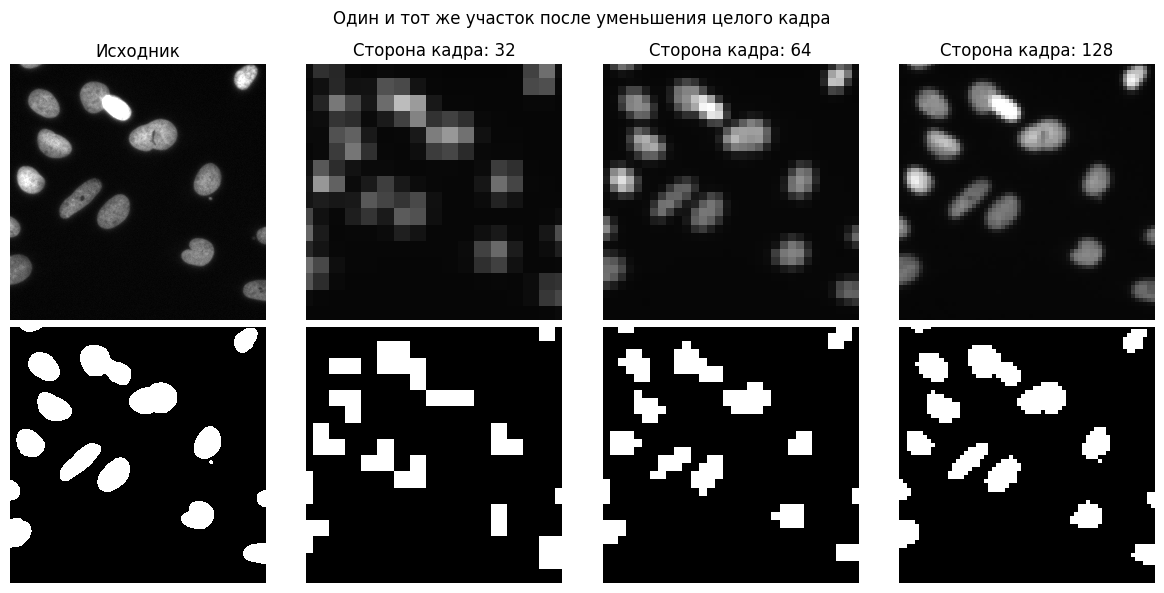

In [7]:
def show_resize_detail(name):
    image, mask = read_pair(name)
    height, width = image.shape
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for column, size in enumerate([None, 32, 64, 128]):
        photo, target = Image.fromarray(image), Image.fromarray(mask)
        if size is not None:
            small = (round(width * size / height), size)
            photo = photo.resize(small, Image.Resampling.BILINEAR).resize((width, height), Image.Resampling.NEAREST)
            target = target.resize(small, Image.Resampling.NEAREST).resize((width, height), Image.Resampling.NEAREST)
        axes[0, column].imshow(center_crop(np.array(photo)), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[1, column].imshow(center_crop(np.array(target)), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[0, column].set_title("Исходник" if size is None else f"Сторона кадра: {size}")
        for ax in axes[:, column]: ax.axis("off")
    fig.suptitle("Один и тот же участок после уменьшения целого кадра")
    plt.tight_layout(); plt.show()

show_resize_detail(train_names[0])


Для обучения будем **вырезать из изображений фрагменты 128×128 без resize**.
Так память и время на шаг будут небольшими, а масштаб ядер сохранится (на полных изображениях каждое ядро будет иметь тот же размер в пикселях).
На каждой эпохе выбираем новые положения кропов внутри train-снимков.

На validation и test подадим целый снимок 520×696. Наша сеть полностью
свёрточная: в ней нет слоев, привязанных к фиксированной ширине и высоте, а значит инференс можно проводить на изображениях любого размера.

## 3. Аугментации: как легко сломать разметку

После отражения снимка ядро всё ещё остаётся ядром, но его координаты изменятся.
Если отразить только изображение, сеть получит правильный класс в неправильном месте:


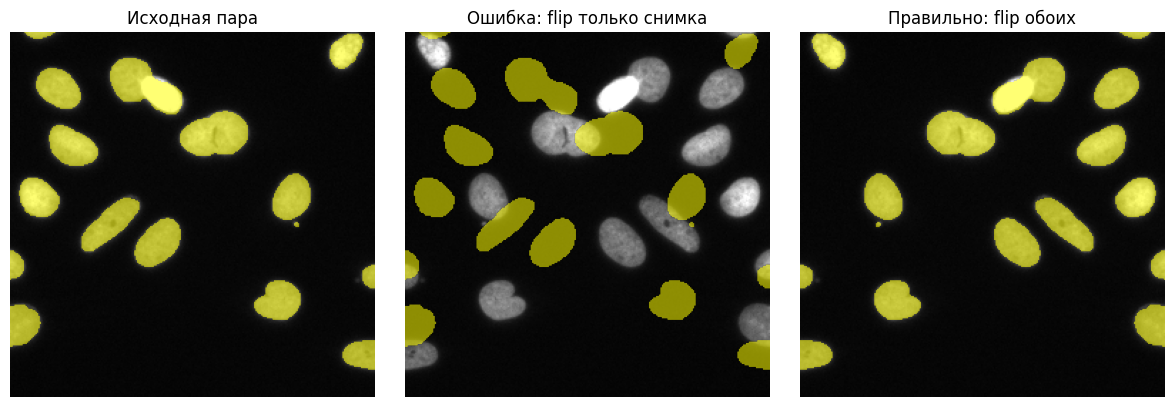

In [8]:
image, mask = read_pair(train_names[0])
image, mask = center_crop(image), center_crop(mask)
flipped_image, flipped_mask = image[:, ::-1], mask[:, ::-1]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, photo, target, title in zip(axes,
        [image, flipped_image, flipped_image], [mask, mask, flipped_mask],
        ["Исходная пара", "Ошибка: flip только снимка", "Правильно: flip обоих"]):
    ax.imshow(photo, cmap="gray", vmin=0, vmax=1)
    ax.imshow(np.ma.masked_where(target != 1, target), cmap="autumn", alpha=.55, vmin=0, vmax=1)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()


На средней картинке снимок и маска больше не совпадают.
Loss будет штрафовать даже правильные предсказания. Если случайно выбирать flip
для снимка и маски независимо, ошибка появится лишь на части примеров - заметить её сложнее.

Есть ещё три частые ловушки:

| Преобразование | Ошибка | Как правильно |
|---|---|---|
| Crop, поворот, сдвиг | Два независимых набора случайных параметров | Один набор параметров для снимка и маски |
| Resize маски | Bilinear смешивает номера классов | Для дискретной маски - nearest интерполяция|
| Яркость, контраст, цвет | Меняем значения в маске вместе со снимком | Меняем только изображение; метки остаются прежними |

Между классами `0` и `1` нет «класса 0.4». Поэтому маску нельзя обрабатывать
как обычное цветное изображение.


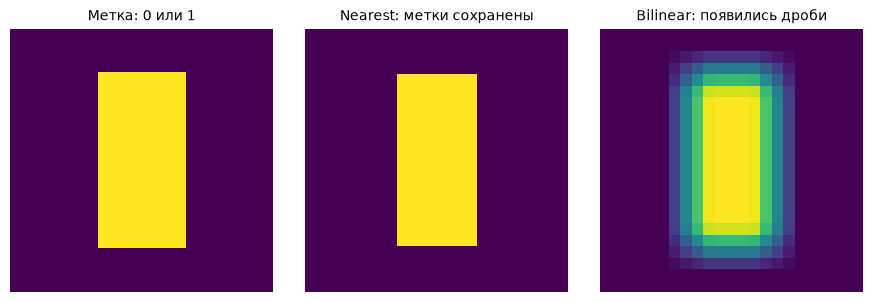


In [9]:
toy = np.zeros((6, 6), dtype=np.float32)
toy[1:5, 2:4] = 1
nearest = np.array(Image.fromarray(toy).resize((23, 23), Image.Resampling.NEAREST))
bilinear = np.array(Image.fromarray(toy).resize((23, 23), Image.Resampling.BILINEAR))
print("Nearest:", np.unique(nearest))
print("Примеры дробных меток:", np.unique(bilinear[(bilinear > 0) & (bilinear < 1)])[:6].round(3))


Nearest: [0. 1.]
Примеры дробных меток: [0.03  0.069 0.081 0.109 0.132 0.149]


Для более богатых аугментаций удобно использовать
[Albumentations](https://albumentations.ai/docs/3-basic-usage/semantic-segmentation/):
передать `image` и `mask` в один `A.Compose`. Библиотека согласует геометрию,
а изменения яркости применит к изображению. Интерполяцию масок всё равно полезно проверять.

В обоих опытах используем одинаковые простые преобразования: случайный кроп,
отражения и поворот на кратный 90° угол.

Полные нормализованные снимки загрузим в память один раз, потому что датасет маленький и помещается в память. `Dataset` будет возвращать
новые train-кропы с включенной аугментацией, а с выключенной - исходные пары для валидации и теста.


In [10]:
class NucleiDataset(Dataset):
    def __init__(self, names, augment=False):
        self.names, self.augment = list(names), augment
        self.pairs = [read_pair(name) for name in names]
        self.rng = np.random.default_rng(SEED)

    def __len__(self):
        return len(self.names) * (CROPS_PER_IMAGE if self.augment else 1)

    def __getitem__(self, index):
        image, mask = self.pairs[index % len(self.names)]
        if self.augment:
            height, width = image.shape
            top = int(self.rng.integers(height - CROP_SIZE + 1))
            left = int(self.rng.integers(width - CROP_SIZE + 1))
            image = image[top:top+CROP_SIZE, left:left+CROP_SIZE]
            mask = mask[top:top+CROP_SIZE, left:left+CROP_SIZE]
            for axis in [0, 1]:
                if self.rng.random() < .5:
                    image, mask = np.flip(image, axis), np.flip(mask, axis)
            k = int(self.rng.integers(4))
            image, mask = np.rot90(image, k), np.rot90(mask, k)
        return image_tensor(image), torch.from_numpy(np.ascontiguousarray(mask)).long()

train_data = NucleiDataset(train_names, augment=True)
val_data = NucleiDataset(val_names)
val_loader = DataLoader(val_data, batch_size=1, shuffle=False, num_workers=0)
images, masks = next(iter(DataLoader(train_data, batch_size=BATCH_SIZE)))
print("Train-кропы:", images.shape, images.dtype)
print("Маски:", masks.shape, masks.dtype, "| метки:", masks.unique().tolist())
print("Validation: целые снимки", tuple(val_data[0][0].shape))


Train-кропы: torch.Size([8, 1, 128, 128]) torch.float32
Маски: torch.Size([8, 128, 128]) torch.int64 | метки: [0, 1]
Validation: целые снимки (1, 520, 696)


## 4. Начнём с обычной свёрточной сети

Мы уже умеем собирать CNN. Что поменять для сегментации?
**Не будем превращать карту признаков в один вектор.** Вместо `Flatten -> Linear` (или `Global Average Pooling -> Linear`)
сохраним пространственные оси, увеличим карты обратно с помощью upsampling и получим два числа в каждой
позиции: логит фона и логит ядра.

Сначала уменьшаем карты пулингом: сеть видит более широкий контекст и может
отличить край ядра от яркого шума. Затем увеличиваем карты интерполяцией
и уточняем свёртками. Эти части также называют **encoder** и **decoder**, вы можете помнить их по уроку про MLP.

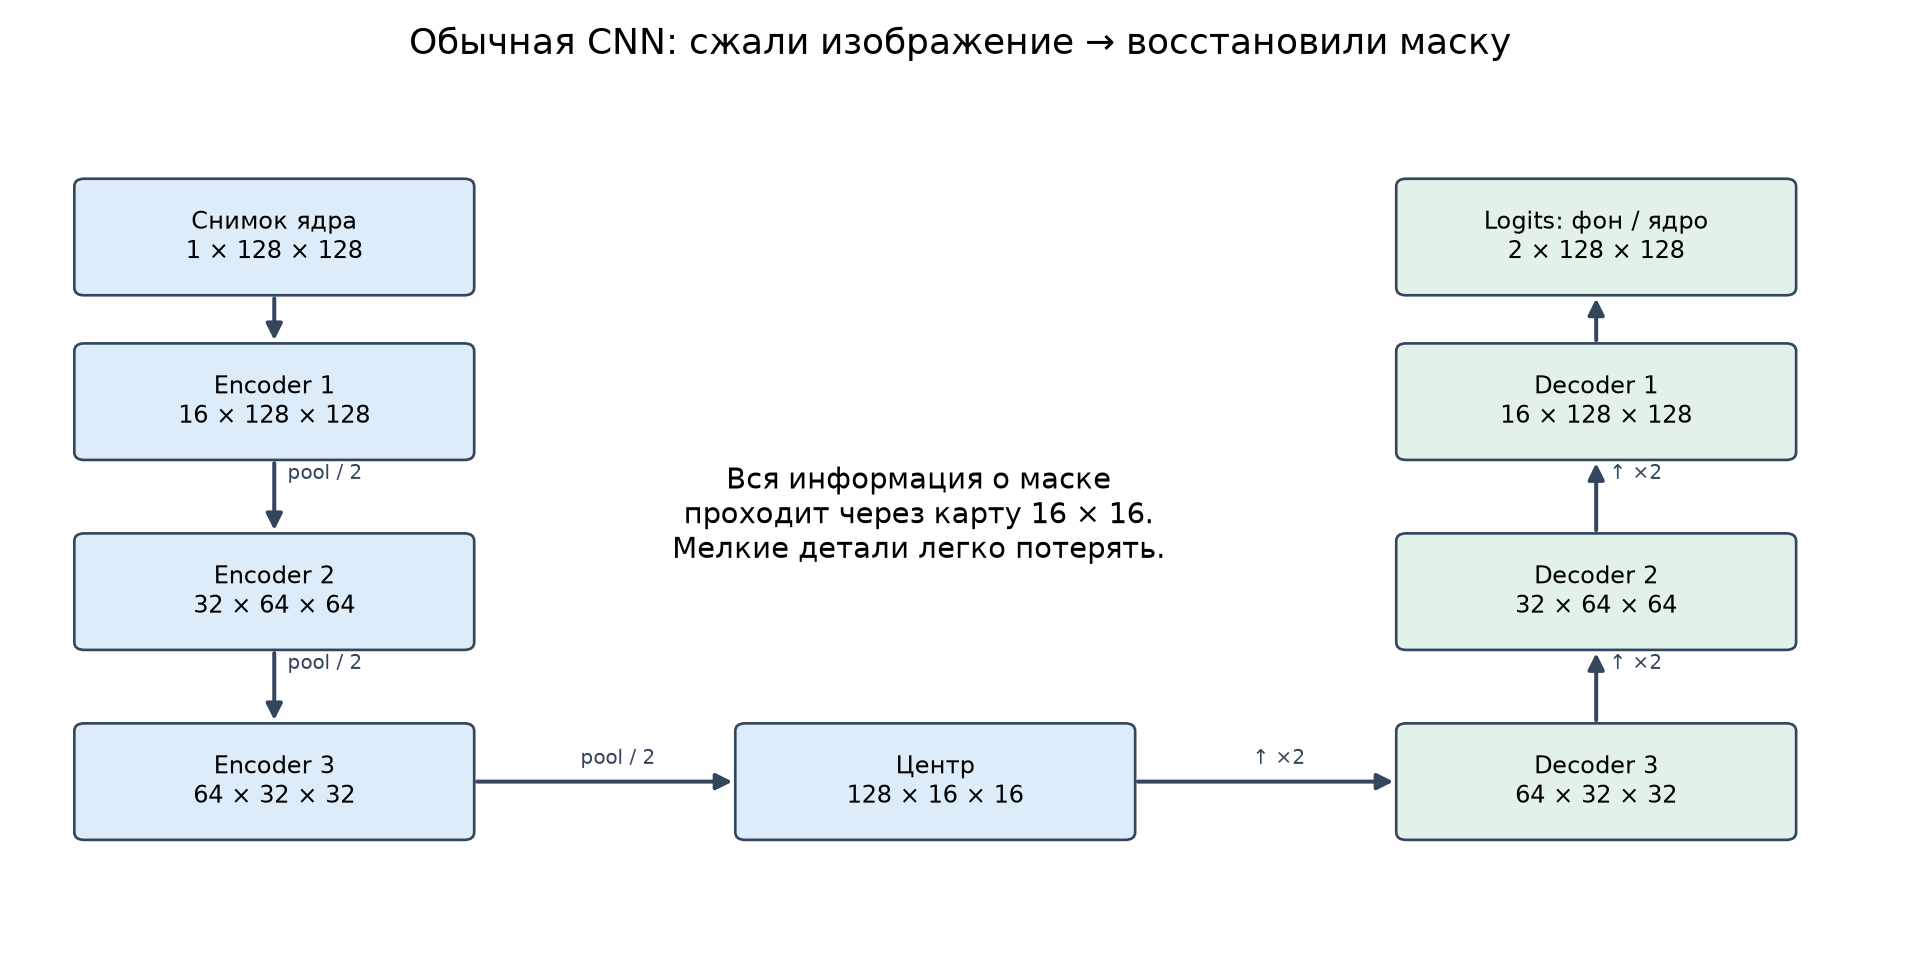


Размеры на схеме - `C × H × W` для кропа `128×128`; ось батча опущена.
В каждом блоке две свёртки `3×3`, BatchNorm и ReLU.
Свёртка `1×1` в конце превращает 16 признаков в два логита.

In [11]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels), nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels), nn.ReLU(),
    )

def up_to(x, reference):
    return F.interpolate(x, size=reference.shape[-2:], mode="bilinear", align_corners=False)

class PlainCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = conv_block(1, 16)
        self.enc2 = conv_block(16, 32)
        self.enc3 = conv_block(32, 64)
        self.center = conv_block(64, 128)
        self.dec3 = conv_block(128, 64)
        self.dec2 = conv_block(64, 32)
        self.dec1 = conv_block(32, 16)
        self.head = nn.Conv2d(16, 2, 1)

    def forward(self, x):
        first = self.enc1(x)
        second = self.enc2(F.max_pool2d(first, 2))
        third = self.enc3(F.max_pool2d(second, 2))
        x = self.center(F.max_pool2d(third, 2))
        x = self.dec3(up_to(x, third))
        x = self.dec2(up_to(x, second))
        x = self.dec1(up_to(x, first))
        return self.head(x)

shape_model = PlainCNN().eval()
with torch.inference_mode():
    print("Вход:", images[:2].shape, "-> logits:", shape_model(images[:2]).shape)
del shape_model


Вход: torch.Size([2, 1, 128, 128]) -> logits: torch.Size([2, 2, 128, 128])


### Как сравнивать маски?

Accuracy может обмануть: если фон занимает большую часть кадра, ответ «везде фон»
уже получает много правильных пикселей. **Intersection over Union (IoU)** проверяет перекрытие:
площадь пересечения правильной и предсказанной масок делим на площадь объединения.
В примере ниже 4 общих пикселя из 14, значит IoU = 4/14 ≈ 0.286.

Для выбора модели используем **global mIoU**: считаем IoU фона и ядер, затем усредняем два числа.

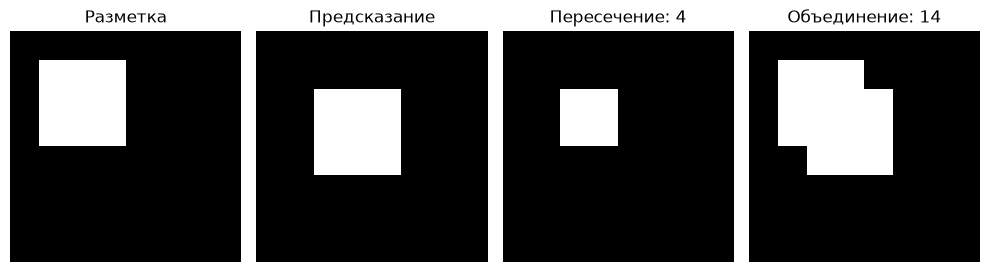


In [12]:
def confusion_matrix(target, prediction):
    valid = target != 255
    codes = 2 * target[valid].astype(np.int64) + prediction[valid].astype(np.int64)
    return np.bincount(codes, minlength=4).reshape(2, 2)

def class_iou(matrix):
    intersection = np.diag(matrix).astype(float)
    union = matrix.sum(0) + matrix.sum(1) - intersection
    return np.divide(intersection, union, out=np.full(2, np.nan), where=union > 0)

def mean_iou(matrix):
    if matrix.sum() == 0:
        raise ValueError("Нет пикселей для оценки")
    return float(np.nanmean(class_iou(matrix)))

target = np.zeros((8, 8), dtype=np.uint8); target[1:4, 1:4] = 1
prediction = np.zeros_like(target); prediction[2:5, 2:5] = 1
print(f"IoU объекта: {class_iou(confusion_matrix(target, prediction))[1]:.3f}")
background = np.zeros_like(target)
print(f"Везде фон: accuracy = {(background == target).mean():.1%}, mIoU = {mean_iou(confusion_matrix(target, background)):.3f}")


IoU объекта: 0.286
Везде фон: accuracy = 85.9%, mIoU = 0.430


### F1 границ: насколько точно проведён контур?

IoU сравнивает **площади** масок. Но можно неплохо угадать площадь ядра и при этом
сгладить выемку на его краю или перекрыть узкий промежуток между соседями.
Чтобы внимательнее посмотреть на такие ошибки, сравним **границы** масок.

**Сначала оставим только контур.** Из каждой бинарной маски уберём внутренние
пиксели объекта. Останется тонкая полоска вдоль его края - граница изнутри маски.
В коде для этого используется [эрозия](https://en.wikipedia.org/wiki/Erosion_(morphology)): она сжимает белую область, а разность
исходной и сжатой масок оставляет край. Фон внутри кадра сам по себе в счёт не идёт.

**Почему не требуем точного совпадения пиксель в пиксель?** Даже небольшой сдвиг
почти правильного контура может убрать большинство точных совпадений.
Поэтому зададим допуск: пиксель одного контура считаем найденным, если рядом
есть хотя бы один пиксель другого контура. Здесь «рядом» - не более двух шагов
вверх, вниз, влево или вправо. Например, два шага вправо или один вправо и один
вверх укладываются в допуск. Считаем шаги в **исходном разрешении снимка**.

Теперь зададим два разных вопроса:

- **Precision границ:** какая доля нарисованного сетью контура находится рядом
  с правильным? Лишние края, например вокруг шума на фоне, уменьшают precision.
- **Recall границ:** какую долю правильного контура удалось найти рядом
  с предсказанным? Пропущенное ядро или часть его края уменьшают recall.

**Пример.** Пусть в правильном контуре 100 пикселей, а сеть нарисовала 120.
Из предсказанных пикселей 90 находятся рядом с правильной границей;
из правильных пикселей 90 имеют рядом предсказанную границу. Тогда:

$$
P = \frac{90}{120} = 0.75, \qquad
R = \frac{90}{100} = 0.90.
$$

Объединим precision и recall в **F1** - их гармоническое среднее:

$$
F1_{\text{границ}} = \frac{2PR}{P+R}
= \frac{2\cdot0.75\cdot0.90}{0.75+0.90}
\approx 0.82.
$$

Чем ближе F1 к 1, тем лучше совпадают контуры **с выбранным допуском**.
Если precision или recall низкий, итоговая F1 тоже снижается.

В `boundary_counts` две операции [дилатации](https://en.wikipedia.org/wiki/Dilation_(morphology)) (`binary_dilation`) создают полосу
допуска вокруг контура. В `evaluate` сначала суммируем числа найденных и всех
граничных пикселей по **всему набору**, а затем считаем P, R и F1.
Больший допуск обычно облегчает совпадение,
поэтому сравнивать результаты нужно при одинаковом допуске и разрешении.

F1 границ здесь помогает разбирать ошибки. Checkpoint и модель по-прежнему
выбираем по validation mIoU.


### Посмотрим на расчёт по шагам

Возьмём маленькие учебные маски. Большой объект предсказан со сдвигом,
маленький пропущен, а в другом месте появилось лишнее пятно.
Одна клетка на схеме — один пиксель. Сверху синяя разметка, снизу оранжевое предсказание.

Двигаемся слева направо: исходная маска -> эрозия -> разность маски и её эрозии
(граница) -> расширение границы на два шага. Расширяем именно тонкий контур:
получается полоса допуска и снаружи, и внутри объекта.


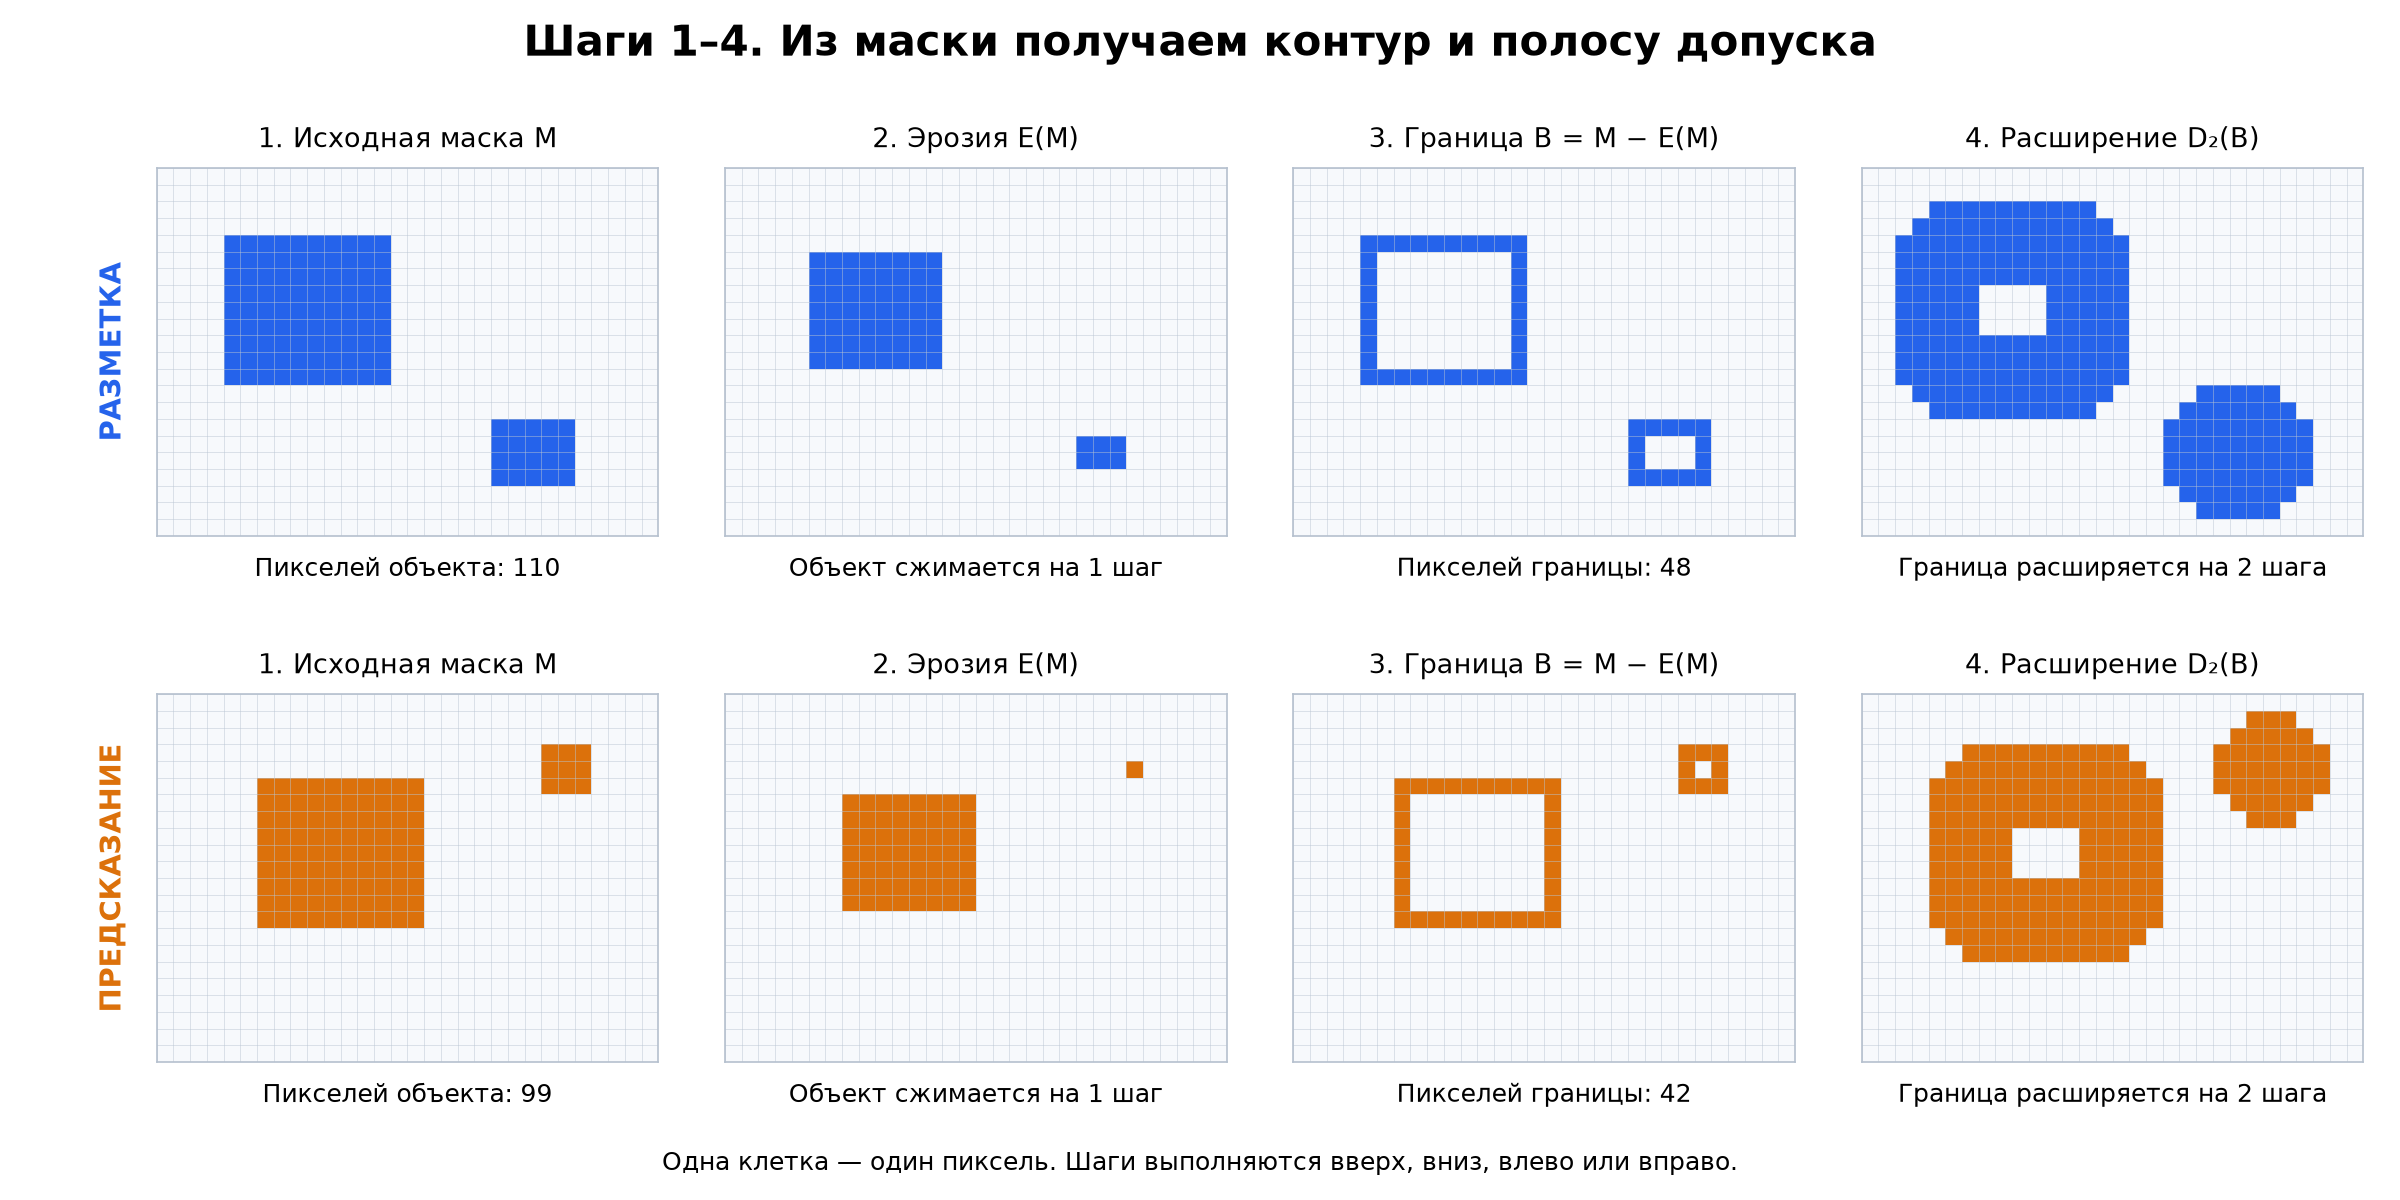


Теперь найдём **пересечения с полосой допуска**:

- Для precision оставляем пиксели **предсказанной границы**, попавшие в расширенную
  границу разметки: `Bпред ∩ D₂(Bразм)`.
- Для recall оставляем пиксели **границы разметки**, попавшие в расширенную
  предсказанную границу: `Bразм ∩ D₂(Bпред)`.

Зелёным показаны найденные пиксели, а оставшиеся оранжевые и синие — ошибки.
Слева для сравнения дано точное пересечение без допуска: совпали всего 2 пикселя.
С допуском найдены 33 из 42 пикселей предсказанной границы и 33 из 48 пикселей
границы разметки. Получаем `P ≈ 0.786`, `R ≈ 0.688`, **`F1 ≈ 0.733`**.
В других примерах два числителя могут различаться: проверку близости выполняем
отдельно в каждую сторону.


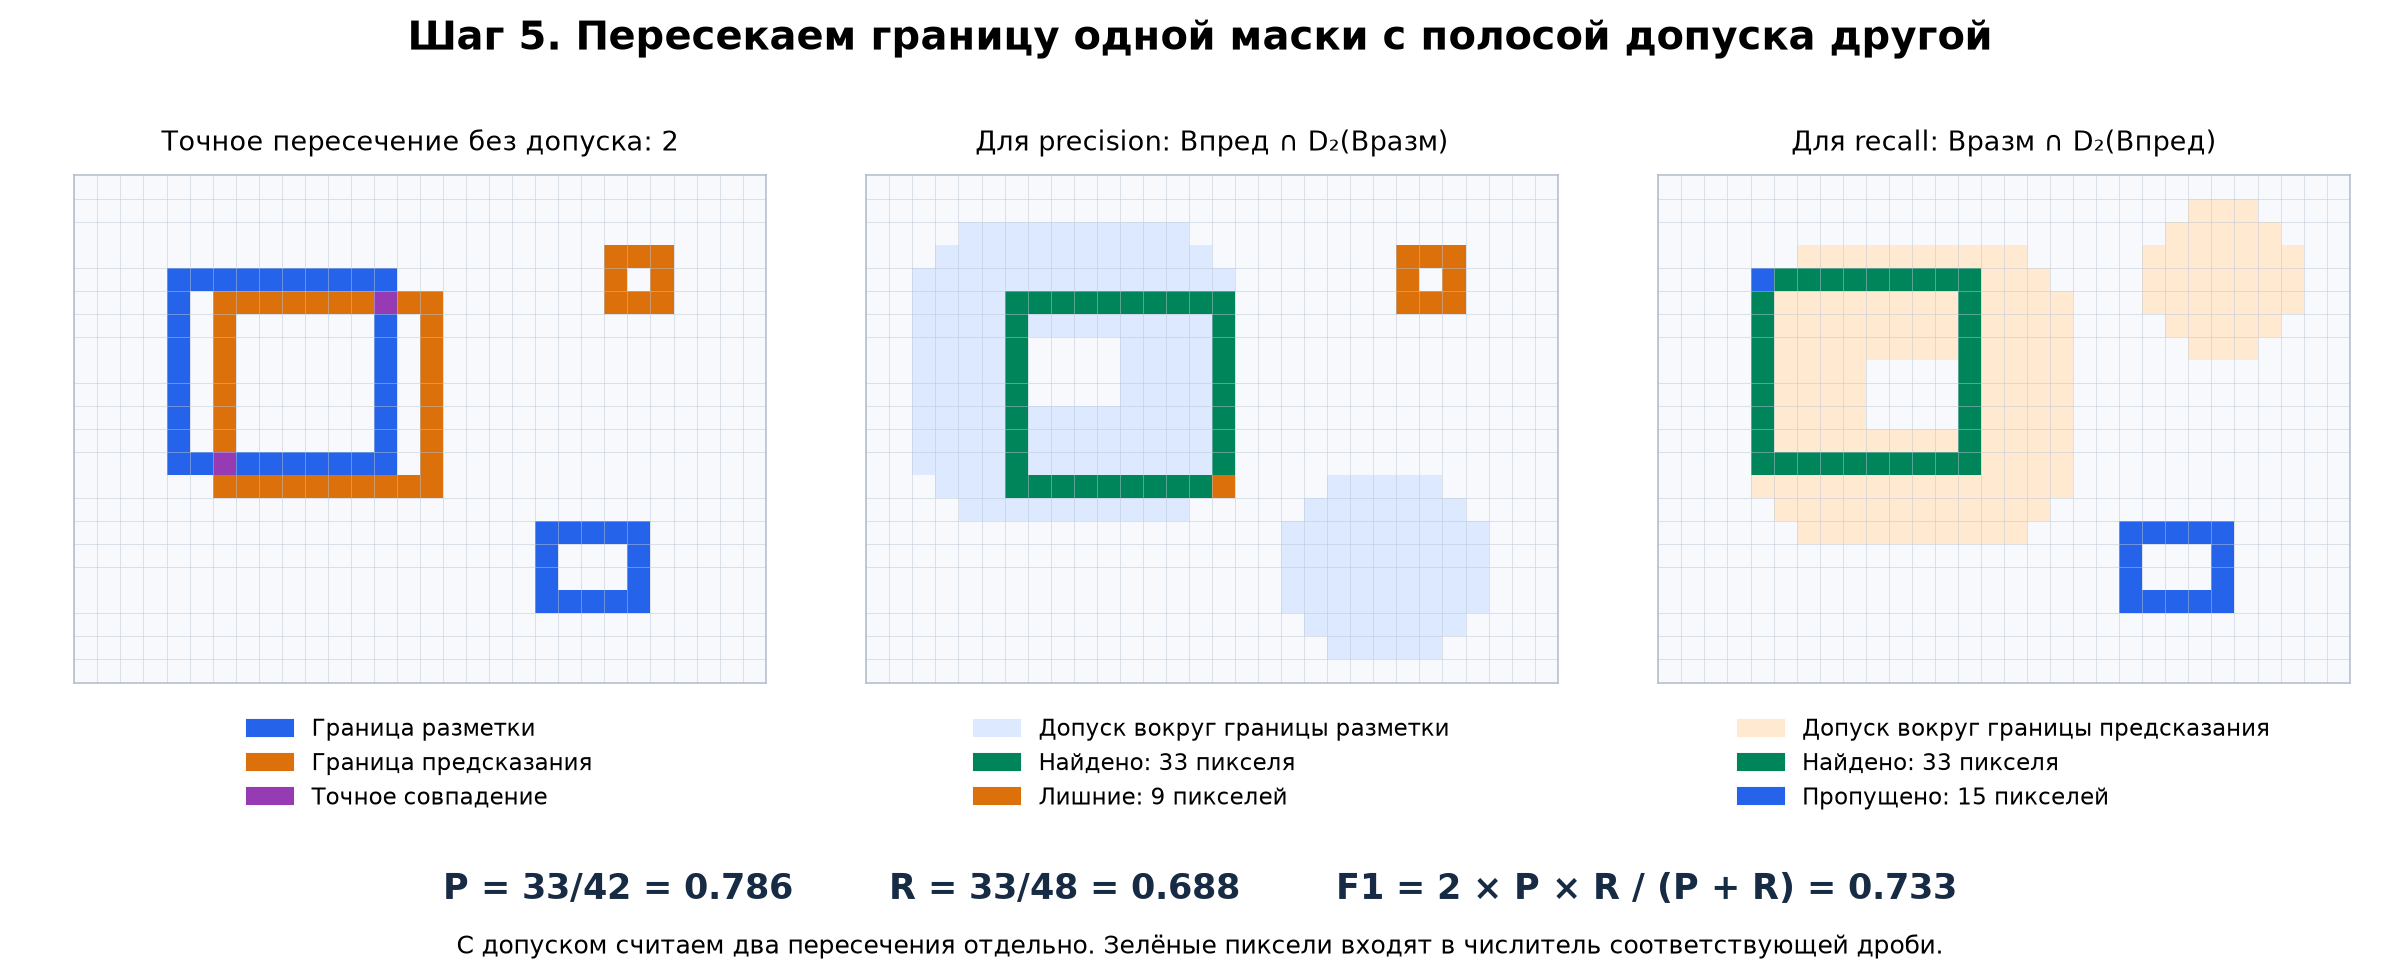


### Обучаем первую модель

После каждой эпохи проверяем
validation и сохраняем лучшие веса. В настройках по умолчанию это 8 эпох
по 25 шагов; обе сети увидят одинаковую последовательность кропов и аугментаций.
В checkpoint запишем архитектуру, нормализацию, классы и split.


In [13]:
criterion = nn.CrossEntropyLoss(ignore_index=255)

def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, total_pixels = 0., 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        count = int((y != 255).sum())
        if count == 0:
            continue
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * count
        total_pixels += count
    return total_loss / total_pixels

def boundary_counts(target, prediction):
    # Контур = маска минус эрозия. Две dilation дают допуск 2.
    foreground, predicted = target == 1, prediction == 1
    true_edge = foreground ^ ndimage.binary_erosion(foreground)
    pred_edge = predicted ^ ndimage.binary_erosion(predicted)
    matched_pred = (pred_edge & ndimage.binary_dilation(true_edge, iterations=2)).sum()
    matched_true = (true_edge & ndimage.binary_dilation(pred_edge, iterations=2)).sum()
    return np.array([matched_pred, pred_edge.sum(), matched_true, true_edge.sum()], dtype=np.int64)

@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    matrix = np.zeros((2, 2), dtype=np.int64)
    edges = np.zeros(4, dtype=np.int64)
    scores, offset = [], 0
    for x, targets in loader:
        predictions = model(x.to(DEVICE)).argmax(1).cpu().numpy()
        for prediction, target in zip(predictions, targets.numpy()):
            counts = confusion_matrix(target, prediction)
            matrix += counts
            edges += boundary_counts(target, prediction)
            scores.append((float(class_iou(counts)[1]), loader.dataset.names[offset]))
            offset += 1
    precision = edges[0] / max(edges[1], 1)
    recall = edges[2] / max(edges[3], 1)
    boundary_f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return mean_iou(matrix), class_iou(matrix), scores, float(boundary_f1)

@torch.inference_mode()
def predict(model, image):
    model.eval()
    logits = model(image_tensor(image)[None].to(DEVICE))
    return logits.argmax(1)[0].cpu().numpy().astype(np.uint8)

def fit(model_class, tag):
    set_seed(SEED)
    train_data.rng = np.random.default_rng(SEED)
    loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                        generator=torch.Generator().manual_seed(SEED))
    model = model_class().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    path = WORK / f"{tag}.pt"
    best, history, snapshots = -1., [], {}
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        loss = train_epoch(model, loader, optimizer)
        score, _, _, _ = evaluate(model, val_loader)
        history.append({"epoch": epoch, "train_loss": loss, "val_miou": score})
        if epoch in {1, max(1, EPOCHS // 2), EPOCHS}:
            snapshots[epoch] = predict(model, val_data.pairs[0][0])
        if score > best:
            best = score
            torch.save({"model": model.state_dict(), "architecture": model_class.__name__,
                        "input_channels": 1, "crop_size": CROP_SIZE,
                        "class_names": ["background", "nucleus"],
                        "raw_mapping": "PNG first channel: zero -> 0, positive -> 1; alpha ignored",
                        "ignore_index": 255, "percentiles": list(PERCENTILES),
                        "preprocessing": "float32 TIFF; per-image percentiles, clip to [0,1]",
                        "inference": "whole image at native resolution; argmax of logits",
                        "seed": SEED, "epoch": epoch, "val_miou": score,
                        "batch_size": BATCH_SIZE, "epochs": EPOCHS, "learning_rate": LEARNING_RATE,
                        "crops_per_image": CROPS_PER_IMAGE,
                        "augmentation": "paired random crop, flips on both axes, rot90",
                        "splits": {"train": train_names, "val": val_names, "test": test_names}}, path)
        print(f"{tag} {epoch:02d}/{EPOCHS}: loss {loss:.3f} | val mIoU {score:.4f}", flush=True)
    elapsed = time.perf_counter() - started
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint["model"])
    score, ious, _, boundary_f1 = evaluate(model, val_loader)
    print(f"Лучший val mIoU: {score:.4f}, эпоха {checkpoint['epoch']}; {elapsed / 60:.1f} мин.")
    return model, {"name": tag, "path": path, "miou": score, "foreground_iou": float(ious[1]),
                   "boundary_f1": boundary_f1, "epoch": checkpoint["epoch"], "seconds": elapsed,
                   "parameters": sum(p.numel() for p in model.parameters()),
                   "history": history, "snapshots": snapshots}

plain_model, plain_result = fit(PlainCNN, "plain_cnn")


plain_cnn 01/8: loss 0.433 | val mIoU 0.7995
plain_cnn 02/8: loss 0.280 | val mIoU 0.8034
plain_cnn 03/8: loss 0.221 | val mIoU 0.7213
plain_cnn 04/8: loss 0.165 | val mIoU 0.9216
plain_cnn 05/8: loss 0.133 | val mIoU 0.9159
plain_cnn 06/8: loss 0.111 | val mIoU 0.8915
plain_cnn 07/8: loss 0.103 | val mIoU 0.8978
plain_cnn 08/8: loss 0.086 | val mIoU 0.9224
Лучший val mIoU: 0.9224, эпоха 8; 0.5 мин.


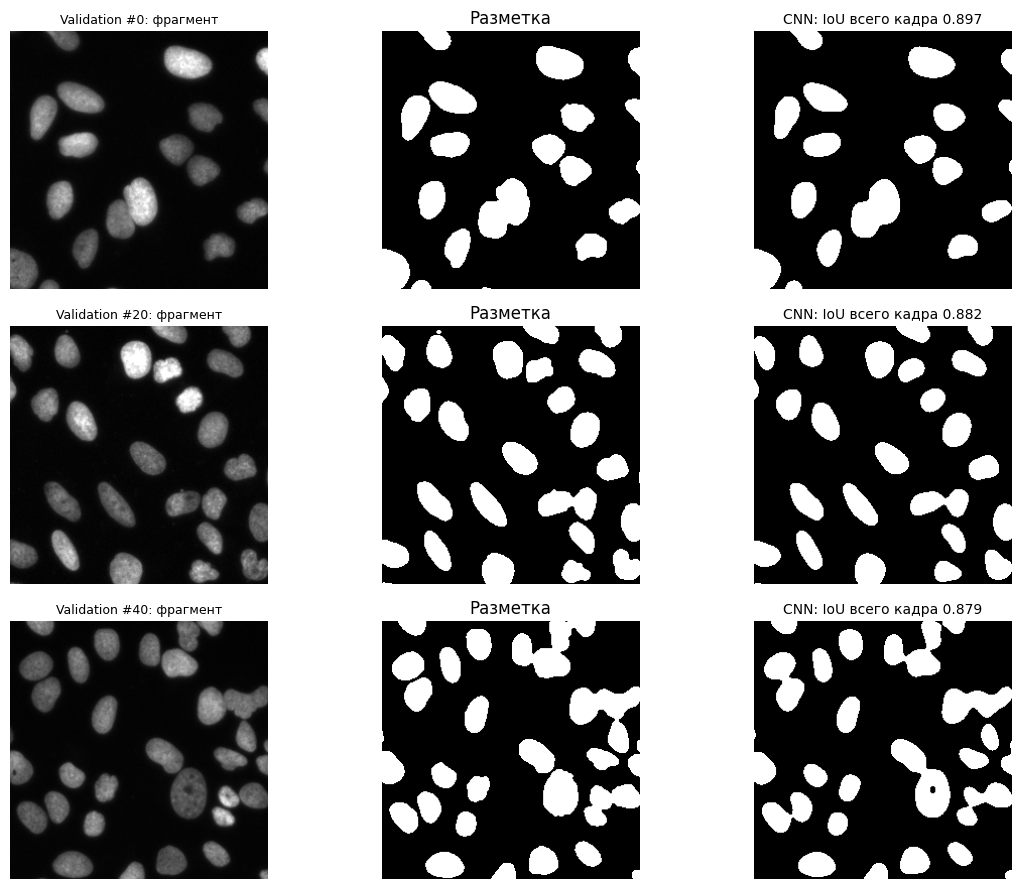

In [14]:
def compare_masks(models, names):
    fig, axes = plt.subplots(len(names), 2 + len(models), figsize=(12, 3 * len(names)), squeeze=False)
    for row, name in zip(axes, names):
        image, target = read_pair(name)
        row[0].imshow(center_crop(image), cmap="gray", vmin=0, vmax=1)
        row[0].set_title(f"Validation #{val_names.index(name)}: фрагмент", fontsize=9)
        row[1].imshow(center_crop(target), cmap="gray", vmin=0, vmax=1); row[1].set_title("Разметка")
        for ax, (title, model) in zip(row[2:], models.items()):
            prediction = predict(model, image)
            score = class_iou(confusion_matrix(target, prediction))[1]
            ax.imshow(center_crop(prediction), cmap="gray", vmin=0, vmax=1)
            ax.set_title(f"{title}: IoU всего кадра {score:.3f}", fontsize=10)
        for ax in row: ax.axis("off")
    plt.tight_layout(); plt.show()

comparison_names = [val_names[i] for i in [0, 20, 40]]
compare_masks({"CNN": plain_model}, comparison_names)


## 5. Зачем тогда U-Net?

Обычная CNN уже умеет выделять ядра. Теперь присмотритесь к границам:
где-то склеились два соседних объекта, где-то исчезла ли маленькая выемка на контуре
Чтобы понять возможную причину, проследим путь пространственной информации:
`128 -> 64 -> 32 -> 16` пикселей по пространственным осям карт признаков. Decoder получает сильно сжатую карту и должен
восстановить по ней точные координаты границ.

**А что, если передать декодеру признаки до сильного сжатия?** Эта идея и лежит в основе архитектуры U-Net.
Глубокие признаки помогают понять, где находится ядро, а ранние карты сохраняют информацию
о локальных перепадах яркости и положении края. Сеть учится использовать оба источника.


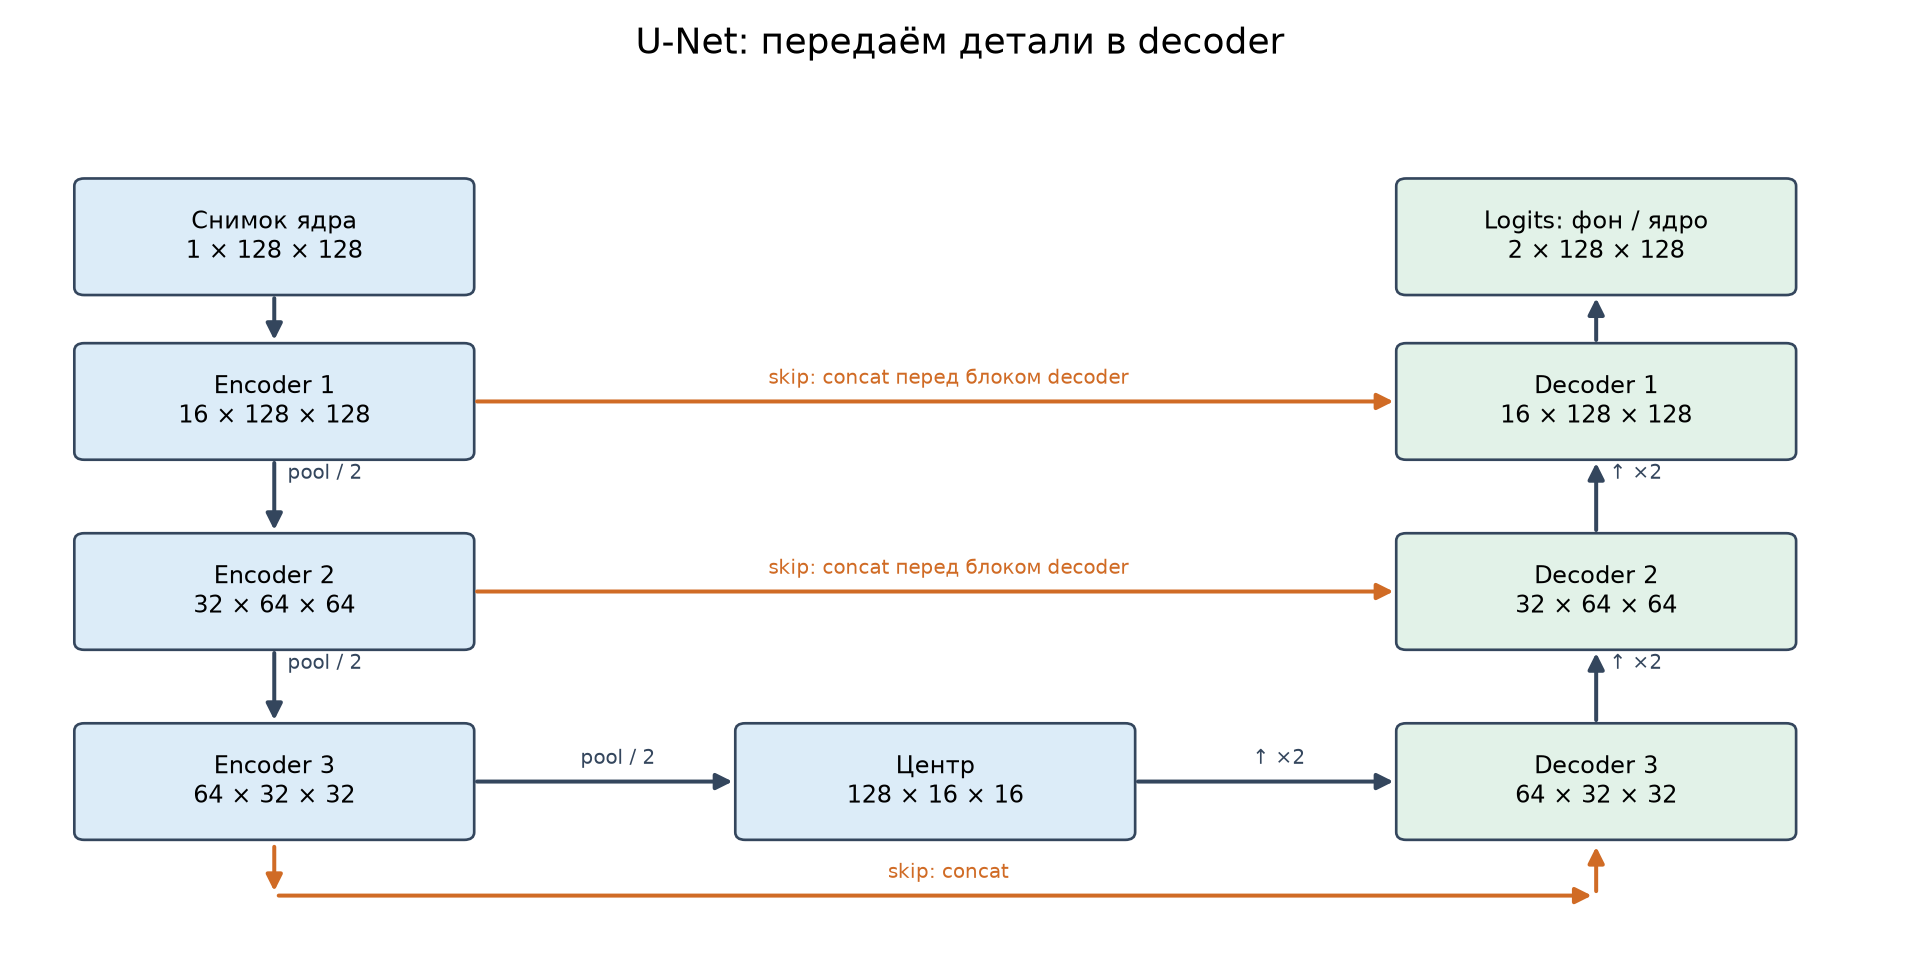


Горизонтальные пути на схеме - **skip-connections**. На каждом уровне увеличиваем
карты признаков декодера, объединяем с картами энкодера и обрабатываем свёртками.
Путь вниз и обратно наверх на этой схеме напоминает букву U - отсюда название архитектуры.

### Два вида Skip-connection

Объединять признаки можно по-разному:

**1. Конкатенация.** Складываем карты «в стопку» по оси каналов.
`32 + 64 = 96` каналов. Значения не складываются: последующая свёртка сама учится
сочетать два набора признаков. Так устроен наш вариант U-Net.


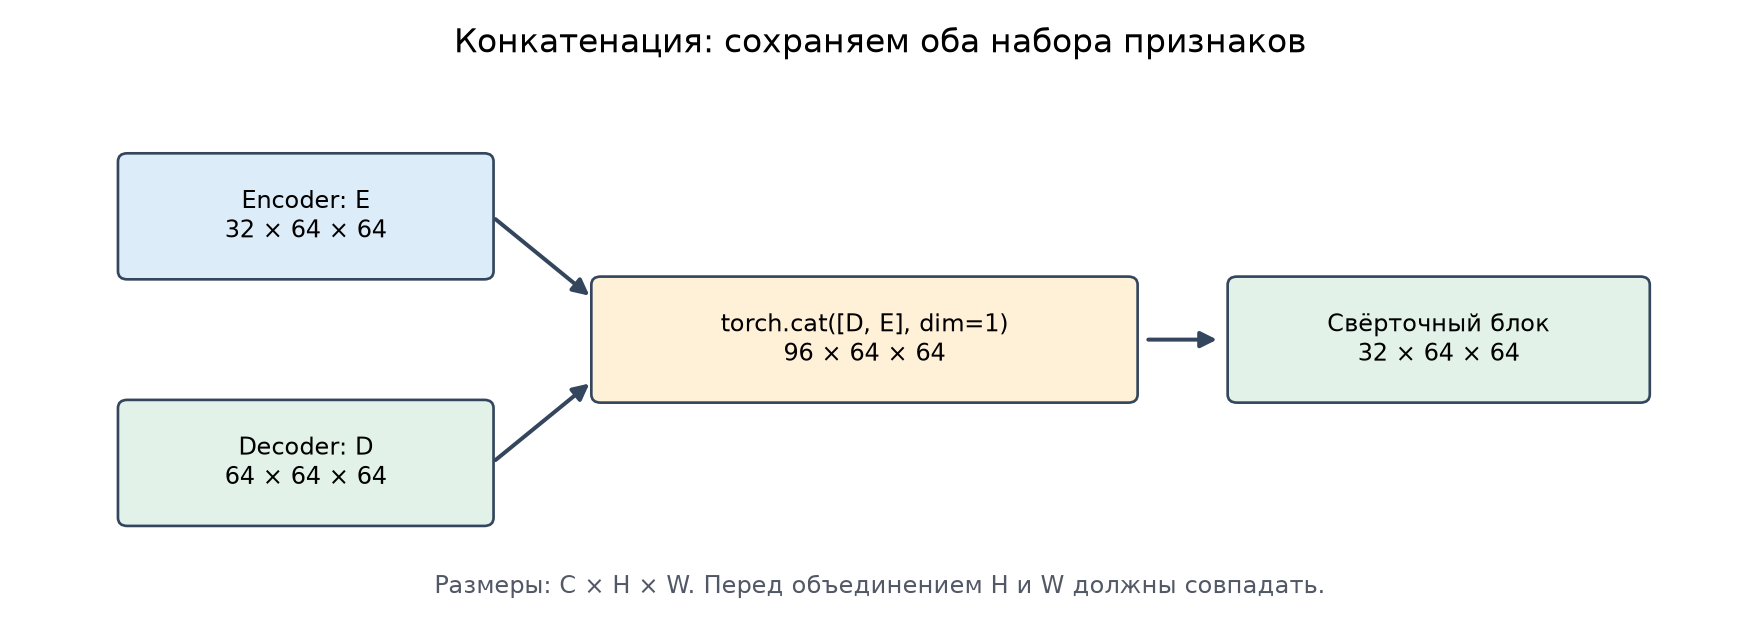


**2. Поэлементное сложение.** Складываем числа в совпадающих позициях.
Нужны одинаковые `H`, `W` **и число каналов**. Если каналов 64 и 32,
сначала обучаемая свёртка `1×1` переводит 64 канала в 32. После суммы остаётся 32.
Подобное сложение знакомо по residual-связям ResNet; путь между encoder и decoder
тоже можно так объединять.


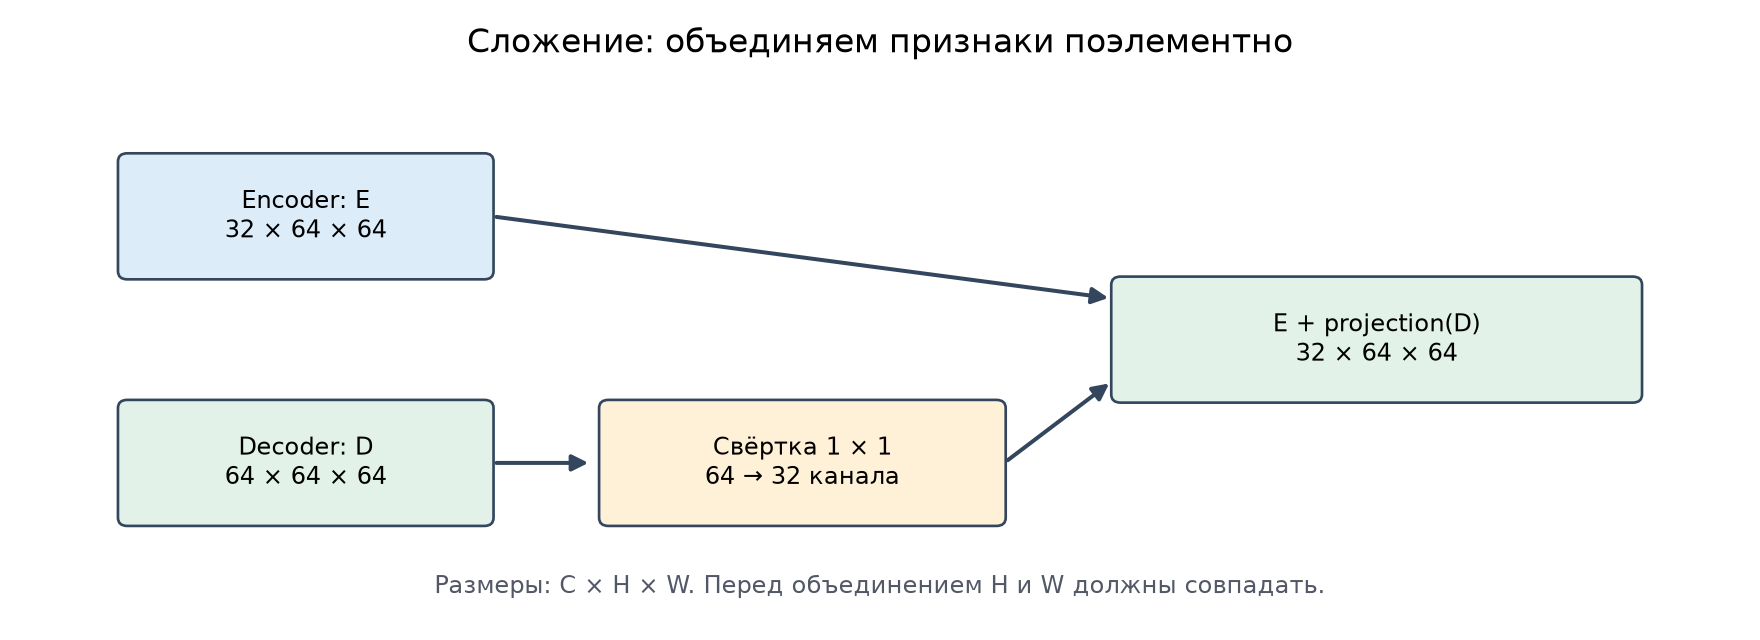


Конкатенация оставляет свёртке оба набора признаков, но увеличивает число входных
каналов и вычисления. Сложение компактнее, однако объединяет их сразу.
Оба вида skip-connection используются в реальных архитектурах. Нужно проверять, какой способ подходит лучше в каждом случае.

In [15]:
e = torch.zeros(1, 32, 64, 64)  # encoder
d = torch.zeros(1, 64, 64, 64)  # decoder уже увеличен до тех же H, W

projection = nn.Conv2d(64, 32, kernel_size=1)
with torch.no_grad():
    concatenated = torch.cat([d, e], dim=1)
    added = projection(d) + e
print("Concat:", tuple(concatenated.shape), "| проекция + сложение:", tuple(added.shape))
del e, d, projection, concatenated, added


Concat: (1, 96, 64, 64) | проекция + сложение: (1, 32, 64, 64)


Унаследуем описание блоков обычной CNN. U-Net создадим заново со случайными весами;
наследование здесь помогает повторно использовать код. Изменятся входы decoder и `forward`:
в трёх местах добавим `torch.cat`. Всё остальное - данные, loss, optimizer,
число эпох и аугментации - оставим прежним.


In [16]:
class MiniUNet(PlainCNN):
    def __init__(self):
        super().__init__()
        self.dec3 = conv_block(128 + 64, 64)
        self.dec2 = conv_block(64 + 32, 32)
        self.dec1 = conv_block(32 + 16, 16)

    def forward(self, x):
        first = self.enc1(x)
        second = self.enc2(F.max_pool2d(first, 2))
        third = self.enc3(F.max_pool2d(second, 2))
        x = self.center(F.max_pool2d(third, 2))
        x = self.dec3(torch.cat([up_to(x, third), third], dim=1))
        x = self.dec2(torch.cat([up_to(x, second), second], dim=1))
        x = self.dec1(torch.cat([up_to(x, first), first], dim=1))
        return self.head(x)

unet_model, unet_result = fit(MiniUNet, "unet")


unet 01/8: loss 0.429 | val mIoU 0.7602
unet 02/8: loss 0.278 | val mIoU 0.8556
unet 03/8: loss 0.219 | val mIoU 0.9246
unet 04/8: loss 0.161 | val mIoU 0.9516
unet 05/8: loss 0.129 | val mIoU 0.9242
unet 06/8: loss 0.105 | val mIoU 0.9188
unet 07/8: loss 0.092 | val mIoU 0.9489
unet 08/8: loss 0.072 | val mIoU 0.9478
Лучший val mIoU: 0.9516, эпоха 4; 0.4 мин.


## 6. Сравним, что получилось

Для каждой сети берём checkpoint с лучшим validation mIoU.
В таблице - метрики по **всем 50 полным validation-снимкам** в исходном разрешении.
На картинках показываем увеличенные центральные фрагменты тех же трёх кадров,
а в подписях - IoU ядер по целому кадру. Фрагмент нужен только для просмотра деталей.

Смотрим на три вещи: общее перекрытие, IoU самих ядер и точность границ.
Параметров у U-Net чуть больше из-за конкатенации, это нормально.


plain_cnn  | mIoU 0.9224 | IoU ядер 0.8748 | F1 границ 0.9348 | эпоха 8 | 439,346 параметров
unet       | mIoU 0.9516 | IoU ядер 0.9223 | F1 границ 0.9579 | эпоха 4 | 487,730 параметров
Разность U-Net − CNN: +0.0292


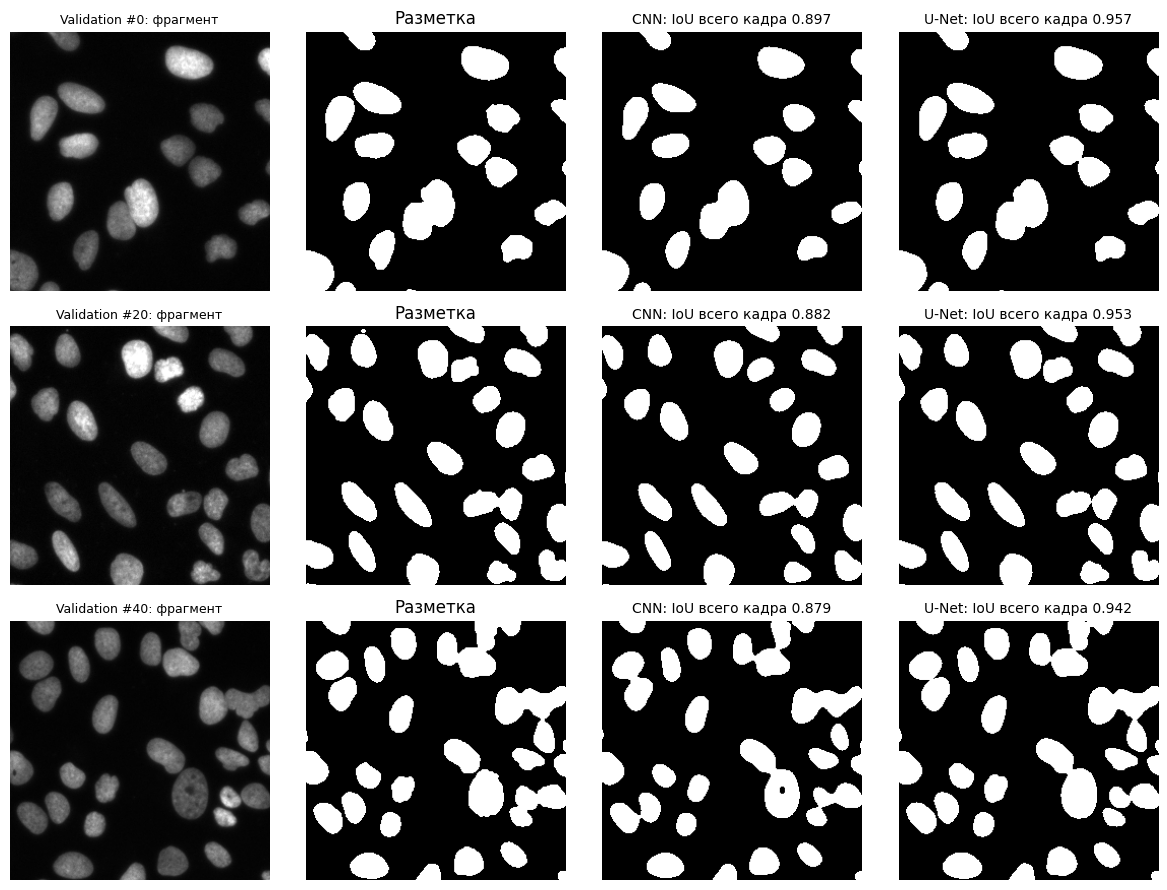

In [17]:
for result in [plain_result, unet_result]:
    print(f"{result['name']:10s} | mIoU {result['miou']:.4f} | IoU ядер {result['foreground_iou']:.4f} | "
          f"F1 границ {result['boundary_f1']:.4f} | эпоха {result['epoch']} | {result['parameters']:,} параметров")
delta = unet_result["miou"] - plain_result["miou"]
print(f"Разность U-Net − CNN: {delta:+.4f}")
compare_masks({"CNN": plain_model, "U-Net": unet_model}, comparison_names)


В проверочном прогоне CNN получила mIoU 0.9455, а U-Net - 0.9544. IoU ядер: 0.9126 -> 0.9269; F1 границ: 0.9602 -> 0.9638. Это оценка целых снимков из валидации обучения по одинаковому рецепту.

Посмотрите на промежутки между близкими ядрами и на небольшие изгибы границы.
Именно здесь полезен доступ decoder к ранним признакам.

Посмотрим ещё, как менялась маска одного и того же снимка при обучении U-Net.


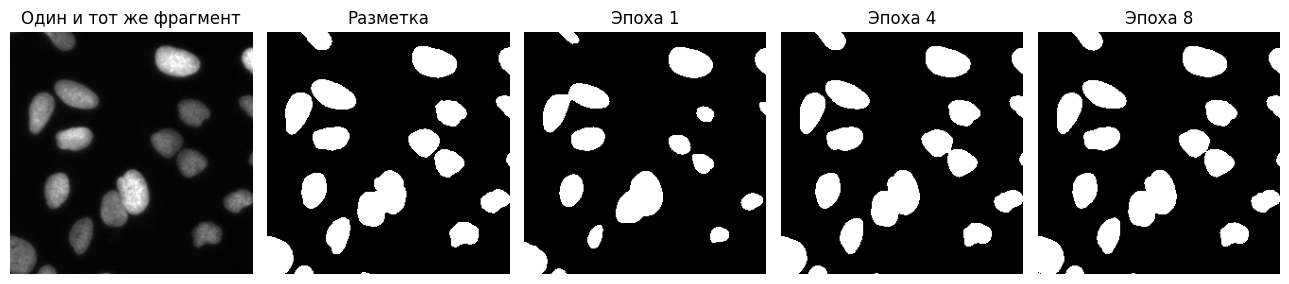

In [18]:
def show_progress(image, target, snapshots):
    fig, axes = plt.subplots(1, 2 + len(snapshots), figsize=(13, 4))
    axes[0].imshow(center_crop(image), cmap="gray", vmin=0, vmax=1); axes[0].set_title("Один и тот же фрагмент")
    axes[1].imshow(center_crop(target), cmap="gray", vmin=0, vmax=1); axes[1].set_title("Разметка")
    for ax, (epoch, prediction) in zip(axes[2:], sorted(snapshots.items())):
        ax.imshow(center_crop(prediction), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Эпоха {epoch}")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

show_progress(*val_data.pairs[0], unet_result["snapshots"])


## 7. Разбираем ошибки лучшей модели

Выберем лучшую модель по качеству на валидации.
Сначала покажем кадр из середины рейтинга по IoU ядер, затем два худших.
Последние два - специально выбранные сложные трудные случаи.
Здесь показываем целые предсказанные маски поверх таргета: красным - лишнее выделение, синим - пропуск.


Выбрана модель: unet
Первая строка - середина рейтинга; две следующие - худшие примеры.


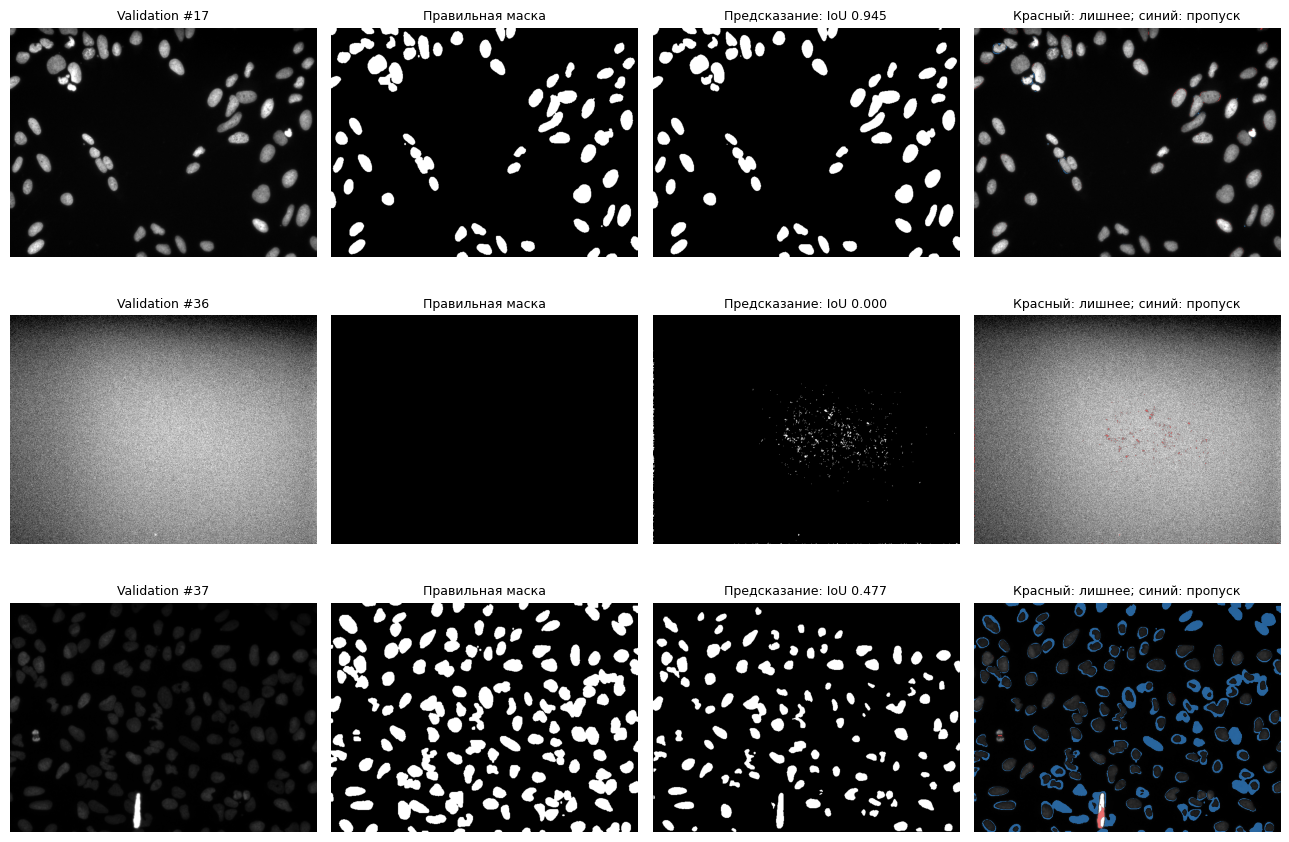

In [19]:
selected_result = max([plain_result, unet_result], key=lambda result: result["miou"])
selected_model = unet_model if selected_result["name"] == "unet" else plain_model
checkpoint_path = selected_result["path"]
print("Выбрана модель:", selected_result["name"])

def show_predictions(model, names):
    fig, axes = plt.subplots(len(names), 4, figsize=(13, 3 * len(names)), squeeze=False)
    for row, name in zip(axes, names):
        image, target = read_pair(name)
        prediction = predict(model, image)
        errors = np.zeros_like(target)
        errors[(target == 0) & (prediction == 1)] = 1
        errors[(target == 1) & (prediction == 0)] = 2
        row[0].imshow(image, cmap="gray", vmin=0, vmax=1)
        row[1].imshow(target, cmap="gray", vmin=0, vmax=1)
        row[2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
        row[3].imshow(image, cmap="gray", vmin=0, vmax=1)
        row[3].imshow(np.ma.masked_where(errors == 0, errors),
                      cmap=ListedColormap(["white", "#e53e3e", "#3182ce"]), vmin=0, vmax=2, alpha=.75)
        score = class_iou(confusion_matrix(target, prediction))[1]
        titles = [f"Validation #{val_names.index(name)}", "Правильная маска", f"Предсказание: IoU {score:.3f}", "Красный: лишнее; синий: пропуск"]
        for ax, title in zip(row, titles): ax.set_title(title, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

_, _, image_scores, _ = evaluate(selected_model, val_loader)
ordered_scores = sorted(image_scores)
middle_name = ordered_scores[len(ordered_scores) // 2][1]
worst_names = [name for score, name in ordered_scores[:2]]
print("Первая строка - середина рейтинга; две следующие - худшие примеры.")
show_predictions(selected_model, [middle_name, *worst_names])


Первая строка показывает обычный результат: IoU ядер
около 0.946. У второго снимка правильная маска пустая, а сеть выделила немного
шума. Поэтому IoU ядер равен нулю: пересечения нет, хотя большинство пикселей
фона предсказано правильно. Возможная причина - нормализация растягивает
слабые колебания яркости пустого кадра, и такие гипотезы нужно отдельно проверять.
На третьем снимке заметны пропуски тусклых ядер и недовыделенные края.

Как можно пробовать исправить ошибки:

- Пропали мелкие ядра -> проверить масштаб и частоту таких объектов в train-кропах.
- Пропадают тусклые ядра -> проверить нормализацию и подходящие изменения яркости.
- Склеились соседи -> рассмотреть узкие промежутки, размер входа и функцию потерь.
- Сеть выделяет яркий шум -> добавить подходящие негативные train-примеры.

### Что скрывает чёрно-белая маска?

`argmax` оставляет только один класс. На карте вероятностей видно, как сильно модель была уверенна в предсказаниях в каждой точке. Значение около 0.5 - неуверенный выбор между двумя классами.
При этом высокая вероятность не гарантирует правильность: сеть может уверенно ошибаться.


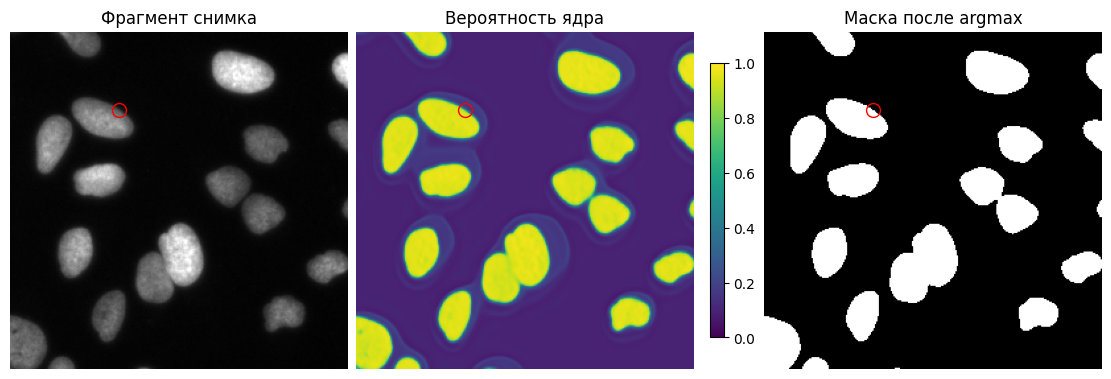

Отмеченный пиксель фрагмента (82, 59): ядро 0.500, фон 0.500. Выбран класс 0.


In [20]:
@torch.inference_mode()
def show_probabilities(model, image):
    model.eval()
    logits = model(image_tensor(image)[None].to(DEVICE))
    probability = center_crop(logits.softmax(1)[0, 1].cpu().numpy())
    prediction = center_crop(logits.argmax(1)[0].cpu().numpy())
    y, x = np.unravel_index(np.abs(probability - .5).argmin(), probability.shape)
    fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout="constrained")
    axes[0].imshow(center_crop(image), cmap="gray", vmin=0, vmax=1)
    heatmap = axes[1].imshow(probability, cmap="viridis", vmin=0, vmax=1)
    axes[2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
    for ax, title in zip(axes, ["Фрагмент снимка", "Вероятность ядра", "Маска после argmax"]):
        ax.plot(x, y, "o", markerfacecolor="none", markeredgecolor="red", markersize=10)
        ax.set_title(title); ax.axis("off")
    fig.colorbar(heatmap, ax=axes[1], shrink=.7)
    plt.show()
    print(f"Отмеченный пиксель фрагмента ({x}, {y}): ядро {probability[y, x]:.3f}, "
          f"фон {1-probability[y, x]:.3f}. Выбран класс {prediction[y, x]}.")

show_probabilities(selected_model, val_data.pairs[0][0])


### Что именно передаётся по skip-связям?

Посмотрим на четыре первых канала encoder и четыре канала в центре U-Net и визуализируем карты признаков. Они показывают отклики
обученных фильтров, по этим визуализациям можно понять, на что модель "смотрит" при предсказании.


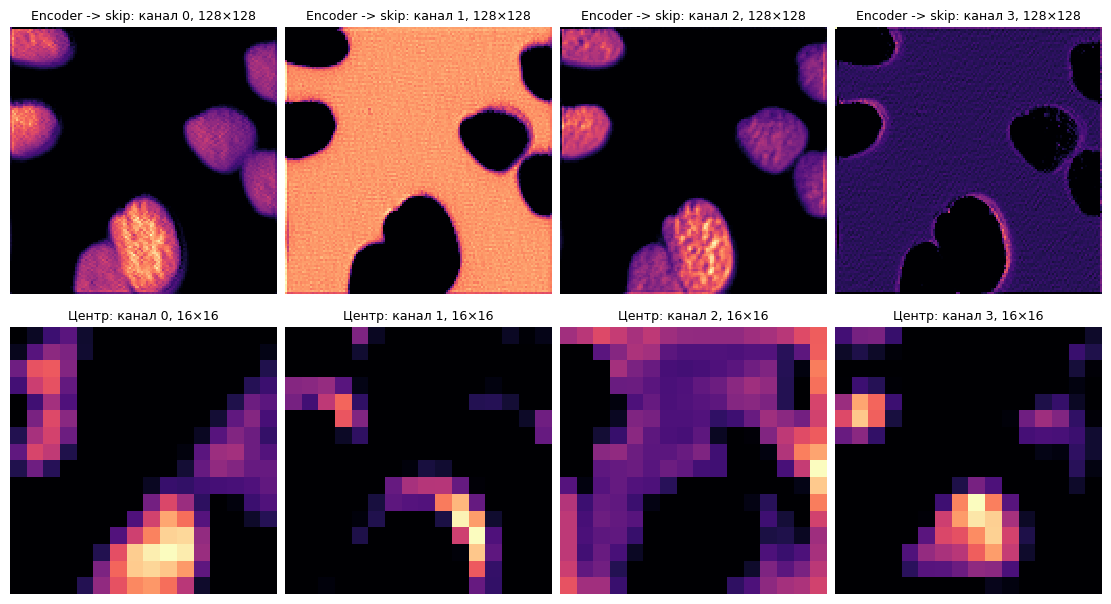

In [21]:
@torch.inference_mode()
def show_features(model, image):
    model.eval()
    x = image_tensor(center_crop(image, CROP_SIZE)).unsqueeze(0).to(DEVICE)
    first = model.enc1(x)
    second = model.enc2(F.max_pool2d(first, 2))
    third = model.enc3(F.max_pool2d(second, 2))
    center = model.center(F.max_pool2d(third, 2))
    fig, axes = plt.subplots(2, 4, figsize=(11, 6), layout="constrained")
    for row, features, label in zip(axes, [first, center], ["Encoder -> skip", "Центр"]):
        height, width = features.shape[-2:]
        for channel, ax in enumerate(row):
            ax.imshow(features[0, channel].cpu().numpy(), cmap="magma", interpolation="nearest")
            ax.set_title(f"{label}: канал {channel}, {height}×{width}", fontsize=9)
            ax.axis("off")
    plt.show()

show_features(unet_model, val_data.pairs[0][0])


## 8. Сохраняем результат и один раз проверяем test

Загрузим выбранный checkpoint в новый объект модели. Для предсказания нужны только
TIFF-снимок, определение архитектуры и checkpoint - правильную маску модель не читает.
Нормализацию возьмём из checkpoint и применим ко всему новому снимку.

Считаем test mIoU на **50 полных снимках**.
Скачайте checkpoint и PNG из `segmentation_lab` до завершения облачной сессии, если хотите сохранить модель и картинки локально.


Test mIoU: 0.9651 | IoU фона: 0.9865 | IoU ядер: 0.9436
Test F1 границ: 0.9860
Маска: IXMtest_A02_s1_w1051DAA7C-7042-435F-99F0-1E847D9B42CB_prediction.png (520, 696) | модель: unet.pt


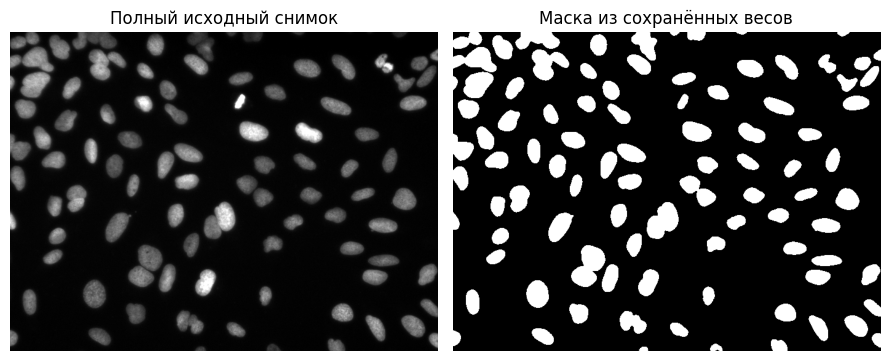

In [22]:
loaded = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
architectures = {"PlainCNN": PlainCNN, "MiniUNet": MiniUNet}
inference_model = architectures[loaded["architecture"]]().to(DEVICE)
inference_model.load_state_dict(loaded["model"])
photo_path = DATA / "images" / f"{val_names[0]}.tif"
photo = load_image(photo_path, loaded["percentiles"])
predicted_mask = predict(inference_model, photo)
assert np.array_equal(predicted_mask, predict(selected_model, photo))
output_path = WORK / f"{photo_path.stem}_prediction.png"
Image.fromarray(predicted_mask).save(output_path)
test_data = NucleiDataset(test_names)
test_loader = DataLoader(test_data, batch_size=1, shuffle=False, num_workers=0)
test_miou, test_ious, _, test_boundary_f1 = evaluate(inference_model, test_loader)
print(f"Test mIoU: {test_miou:.4f} | IoU фона: {test_ious[0]:.4f} | IoU ядер: {test_ious[1]:.4f}")
print(f"Test F1 границ: {test_boundary_f1:.4f}")
print("Маска:", output_path.name, predicted_mask.shape, "| модель:", checkpoint_path.name)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(photo, cmap="gray", vmin=0, vmax=1); axes[0].set_title("Полный исходный снимок")
axes[1].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1); axes[1].set_title("Маска из сохранённых весов")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()


## Дополнительно: размножаем train с помощью copy-paste

Теперь небольшой трюк для получения еще большего количества обучающих примеров: раз есть разметка объектов,
можно вырезать ядро по готовой маске и перенести его на другой фон. Новая маска также переносится.

Возьмём примеры из train: три отдельных фоновых фрагмента без ядер и три ядра-донора.
В исходном первом канале маски соседние ядра могут иметь разные значения.
Поэтому сначала ищем связные компоненты для каждого положительного значения,
а уже затем выбираем отдельный объект. Это полезное применение исходной
instance-разметки, которую мы объединили для основного обучения семантической сегментации.

Фоны выглядят почти чёрными, но сохраняют шум реальных снимков.
Для демострации на каждом фоне повторим одно ядро трижды, меняя масштаб, поворот и положение.


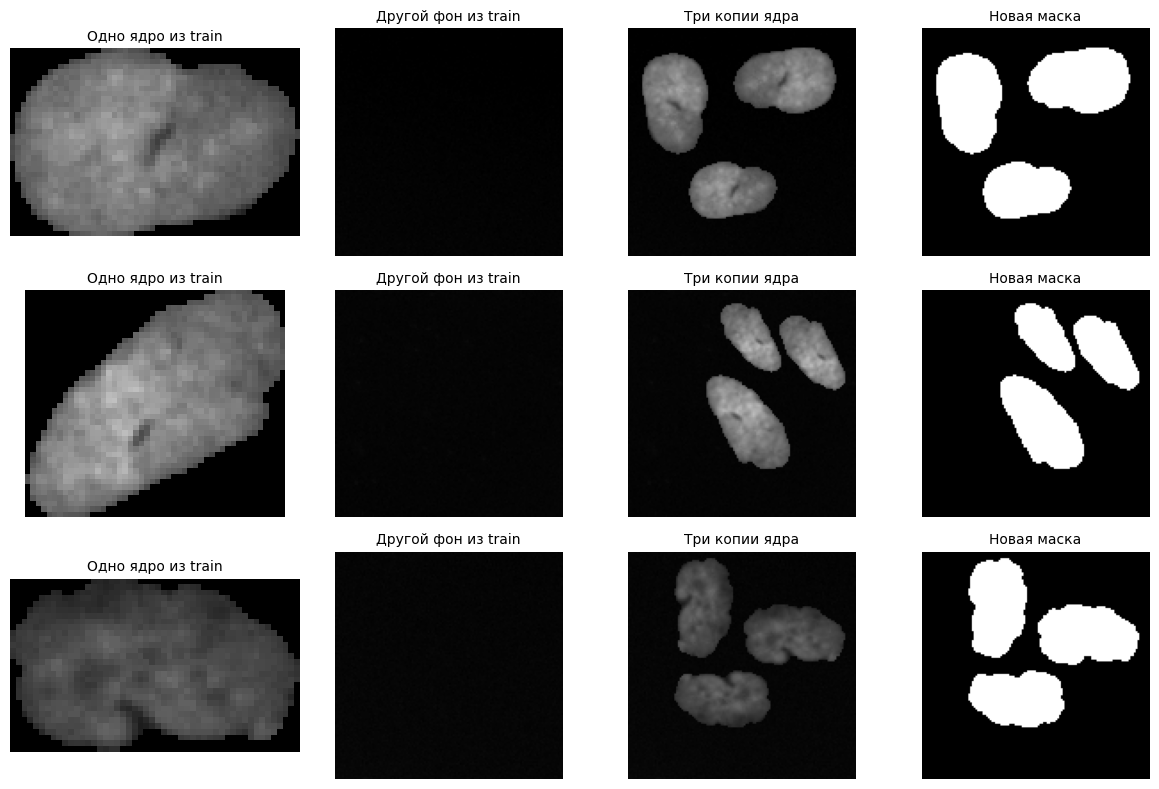

In [23]:
def find_backgrounds(names, count=3, size=128):
    assert set(names) <= set(train_names), "Фоны берём только из train"
    backgrounds = []
    for name in names:
        image, mask = read_pair(name)
        found = False
        for top in range(0, image.shape[0]-size+1, size//2):
            for left in range(0, image.shape[1]-size+1, size//2):
                if not mask[top:top+size, left:left+size].any():
                    backgrounds.append((name, image[top:top+size, left:left+size].copy()))
                    found = True
                    break
            if found: break
        if len(backgrounds) == count: return backgrounds
    raise ValueError("Не нашлось достаточно чистых фонов")

def cut_nucleus(name):
    assert name in train_names, "Доноры берутся только из train"
    image, _ = read_pair(name)
    with Image.open(DATA / "masks" / f"{name}.png") as source:
        raw = np.asarray(source)[..., 0]
    candidates = []
    for value in np.unique(raw):
        if value == 0: continue
        components, _ = ndimage.label(raw == value, structure=np.ones((3, 3)))
        for label_id, region in enumerate(ndimage.find_objects(components), start=1):
            if region is None: continue
            ys, xs = region
            if ys.start == 0 or xs.start == 0 or ys.stop == raw.shape[0] or xs.stop == raw.shape[1]:
                continue  # не берём ядро, обрезанное краем снимка
            object_mask = (components[region] == label_id).astype(np.uint8)
            candidates.append((int(object_mask.sum()), image[region].copy(), object_mask))
    if not candidates: raise ValueError("В снимке нет целого размеченного ядра")
    _, cutout, object_mask = max(candidates, key=lambda item: item[0])
    return cutout, object_mask

def paste_nucleus(image, target, cutout, object_mask, rng):
    k = int(rng.integers(4))
    cutout, object_mask = np.rot90(cutout, k), np.rot90(object_mask, k)
    scale = min(float(rng.uniform(.7, 1.2)), .45 * min(image.shape) / max(cutout.shape))
    height, width = [max(1, round(s * scale)) for s in cutout.shape]
    cutout = np.array(Image.fromarray(cutout).resize((width, height), Image.Resampling.BILINEAR))
    foreground = np.array(Image.fromarray(object_mask).resize((width, height), Image.Resampling.NEAREST)) > 0
    for _ in range(50):
        top = int(rng.integers(image.shape[0]-height+1))
        left = int(rng.integers(image.shape[1]-width+1))
        if not target[top:top+height, left:left+width][foreground].any():
            break
    else:
        raise ValueError("Не нашлось свободного места: уменьшите вырезку")
    image, target = image.copy(), target.copy()
    image[top:top+height, left:left+width][foreground] = cutout[foreground]
    target[top:top+height, left:left+width][foreground] = 1
    return image, target

backgrounds = find_backgrounds(train_names)
synthetic_pairs = []
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
rng = np.random.default_rng(SEED)
for row, (background_name, background), donor in zip(axes, backgrounds, [train_names[i] for i in [0, 20, 40]]):
    cutout, object_mask = cut_nucleus(donor)
    composite, target = background.copy(), np.zeros(background.shape, dtype=np.uint8)
    for _ in range(3):
        composite, target = paste_nucleus(composite, target, cutout, object_mask, rng)
    synthetic_pairs.append((composite, target))
    isolated = np.where(object_mask, cutout, 0)
    for ax, array, title in zip(row, [isolated, background, composite, target],
                               ["Одно ядро из train", "Другой фон из train", "Три копии ядра", "Новая маска"]):
        ax.imshow(array, cmap="gray", vmin=0, vmax=1)
        ax.set_title(title, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()


Маска получилась автоматически, но правдоподобие и соответствие распределению из трейна не гарантируется, сеть рискует выучить следы генерации синтетики, поэтому нужно быть осторожным.

**Как использовать синтетические примеры:** На части train-шагов, например с вероятностью 0.25,
заменяйте исходную пару синтетической. Смешивайте реальные и искусственные примеры,
сохраните validation и сравните при том же вычислительном бюджете.

Это иллюстрация идеи [Simple Copy-Paste](https://arxiv.org/abs/2012.07177).


## Практические советы по сегментации

Хорошее решение начинается с понятных масок и честной проверки качества.
Дальше полезно двигаться от конкретной ошибки к небольшому проверяемому изменению.

1. **Сначала проверьте разметку.** Наложите маски на несколько изображений:
   совпадают ли размеры, координаты и границы? Зафиксируйте номера классов,
   смысл фона и `ignore`. Неразмеченный пиксель не всегда означает фон.
   Если требуется различать отдельные объекты одного класса, нужна instance segmentation.

2. **Разделяйте исходные объекты до создания кропов/других синтетических примеров.** Похожие кадры
   одной сцены, снимки одного объекта и соседние тайлы могут дать утечку между
   train и validation. Сначала сделайте разбиение по независимым группам, затем
   нарезайте кропы и создавайте синтетику.

3. **Выбирайте разрешение по размеру важных деталей.** Посмотрите, что остаётся
   от тонких границ и маленьких объектов после resize. Попробуйте больший вход
   или обучение на кропах; учитывайте память, время обучения и потерю контекста.
   Для больших изображений можно использовать тайлы с перекрытием и усреднять
   логиты в общей области, чтобы уменьшить швы между предсказаниями.

4. **Проверяйте аугментации глазами.** Геометрические параметры должны быть общими
   для фото и маски; цветовые изменения применяются только к изображению,
   а номера классов масштабируются через nearest. Для готовых преобразований
   удобно использовать Albumentations. Copy-paste добавляет примеров,
   но требует аккуратных вырезок, подходящих фонов и проверки доли синтетики.
   Смотрите, не учится ли модель узнавать признаки генерации вместо самих объектов.

5. **Разбирайте ошибки вместе с метрикой.** Смотрите обычные и худшие примеры,
   ложные срабатывания и пропуски, IoU отдельных классов, качество мелких объектов
   и границ. Карта вероятностей помогает увидеть неопределённость, но высокая
   уверенность модели не гарантирует правильность предсказания. Иногда нужно исправить разметку
   или preprocessing прежде чем менять сеть.

6. **Учитывайте дисбаланс классов.** Когда фон занимает почти всё изображение,
   accuracy может скрывать пропущенные объекты. Можно проверить веса классов,
   CE + soft Dice или более частый выбор train-кропов с объектами. Оставляйте и
   отрицательные примеры, сохраняйте реальную частоту объектов в validation
   и корректно исключайте класс `ignore` из лосса и метрик.

7. **Усложняйте модель только по результатам диагностики.** Начните с простой сети,
   затем отдельно сравните ширину, глубину или способ объединения skip-связей.
   При замене concat на сложение согласуйте каналы и входы decoder-блоков.
   Сравнивайте не только качество, но и память и время работы.

8. **Проводите управляемые эксперименты.** Меняйте одно условие за раз:
   разрешение, аугментацию, loss, число эпох или расписание learning rate.
   Записывайте гипотезу, конфигурацию, validation-метрику и время; сравнивайте
   ошибки на одинаковых изображениях. Используйте одинаковые split и seed,
   а перспективное улучшение перепроверьте на нескольких seed.
   Выбирайте checkpoint и пороги предсказаний по валидации.

9. **Следите за геометрией при предсказании.** Например, если вы используете flip-TTA (предсказание на отраженном изображении), сначала отразите ответ обратно,
   затем усредните logits и получите маску. Проверьте ориентацию, размеры,
   значения классов и соответствие результата исходному изображению.
   Дополнительные проходы модели требуют дополнительного времени.

10. **Сохраняйте всё, что нужно для воспроизведения результата.** Вместе с весами
    сохраните архитектуру, размер входа, нормализацию, порядок классов и настройки
    инференса. Загрузите модель в новом процессе и проверьте, что она получает
    тот же ответ без доступа к правильной маске.

Источники урока: [BBBC039v1](https://bbbc.broadinstitute.org/BBBC039),
[Penn-Fudan (вводная иллюстрация)](https://www.cis.upenn.edu/~jshi/ped_html/),
[U-Net](https://arxiv.org/abs/1505.04597),
[остаточные связи ResNet](https://arxiv.org/abs/1512.03385),
[Simple Copy-Paste](https://arxiv.org/abs/2012.07177).
